# Step 4.3 - Morphology vs. transcriptomics, interchangeable anchors and unmixed axes (v4)

**What this notebook does.** The newest version of the Step 4 benchmark. As in Steps 4.1 and 4.2 it measures how much
of the information in image-based (Cell Painting) profiles is shared with a transcriptomic profile of the same
compounds, ranks the image-based models by this shared information, and interprets the shared axes biologically.
Step 4.3 adds three things: the transcriptomic side can be switched between several sources, the shared axes can be
separated into cleaner programs, and the axes are checked against a known biological hypothesis.

**What changed from v3 (Step 4.2)**
* The transcriptomic side (the *anchor*) is a **setting**: raw DRUG-seq genes, the 43 DRUG-seq factors, or latent
  perturbation embeddings from ChemPerturb-Bridge (CPB). The saved run uses the CPB latent embeddings.
* The eight image models are read from the harmonized `indexed_by_inchikey` folder and every table is paired with the
  anchor **by InChIKey**, whatever the name of its key column.
* Four evaluation settings are explicit: how morphology is compressed (`PCA_MODE`), which compounds are compared
  (`COHORT_STRATEGY`: each model on all of its compounds, or every model on the same compounds), how the noise floor
  is defined (`STAT_THRESHOLD_MODE`: a number of standard deviations above the null or a percentile of it) and the
  anchor itself.
* **Axis decoding is richer** (Part 2): the axes can be **unmixed** (Varimax, FastICA or both), the drivers of each axis
  are compared with Chemical Checker *and* by 2D chemical structure (ECFP4 Tanimoto similarity), and a
  **morphology coherence check** asks whether the drivers also look alike in the images.
* **Part 3** scores every axis for *purity*: is it carried by a few genes, and is it just cell stress?
* **Part 4** tests two biological hypotheses about microtubule drugs against the axes.

**Methods in plain language**
* **Linear CKA** (centered kernel alignment) gives one number between 0 and 1: do compounds that look alike in images
  also have similar transcriptomic profiles?
* **SVCCA** (singular vector canonical correlation analysis) reduces each dataset to its main directions of variation
  and then finds pairs of directions, one per dataset, that are as correlated as possible. Each pair is a *canonical
  axis* of shared variation; the sorted correlations form a *decay curve*.
* **Permutation null and noise floor.** Shuffling which transcriptomic profile belongs to which compound shows what
  chance produces. Only axes above the *noise floor* (here: the null mean plus 3 standard deviations) count as
  significant.
* **Unmixing.** A canonical axis can blend several biological programs. *Varimax* rotates the axes so that each
  compound loads strongly on few of them; *FastICA* looks for statistically independent sources; *hybrid* does both.
  The subspace is the same, only the way it is cut into axes changes.
* **Purity.** A good axis is carried by a few genes (heavy-tailed, sparse gene correlations) and is not simply a
  generic stress response.
* **Axis explainers.** Start from a hypothesis (microtubule/mitotic genes, known tubulin drugs) and find the axes that
  track it.

These methods are implemented in the `model_benchmarking` package (`anchors`, `alignment`, `unmixing`, `decoding`,
`chemistry`, `purity`, `explainers`, `plotting`) and covered by unit tests.

**Inputs.** The eight morphology tables and the transcriptomic anchors in `gs://calico-reference-embeddings/indexed_by_inchikey`,
raw DRUG-seq signatures (gene-level decoding), Chemical Checker sign3 for all JUMP compounds and a standardized
SMILES table for the JUMP compounds.

**Hardware.** A GPU speeds things up (the saved run used an NVIDIA V100), but every step falls back to the CPU.

**Run order matters.** Parts 2-4 decode the top-ranked model of the benchmark in Part 1 and reuse its variables
(`leaderboard_df`, `cached_filepaths`, ...), so run the notebook from top to bottom. An internet connection is needed
for MyGene.info, Enrichr, PubChem and ChEMBL.

> ⚠️ **About the saved outputs and known limitations**
> * The saved outputs were produced by the draft notebook this one replaces, before its code was moved into the
>   package. Settings of the saved run: anchor `cpb_latent_distr`, `PCA_MODE="variance"` with 99% variance, a +3σ noise
>   floor, `COHORT_STRATEGY="pairwise"` and `UNMIXING_METHOD="fastica"`. Decoding now uses the exact eigendecomposition
>   (like the benchmark) instead of a randomized low-rank PCA, so the exact numbers of Part 2 may differ slightly.
> * Part 4 has no saved output. The draft's Part 4 outputs came from an older session (523 compounds, factor-based
>   axes), and its drug list contained wrong InChIKeys (see Part 4), so those outputs are not reproducible.
> * With pairwise cohorts the models are scored on different compounds (N = 1,551 vs. 2,669 in the saved run), so
>   adjusted AUCs are not strictly comparable; use `COHORT_STRATEGY = "common"` for a like-for-like comparison.
> * Canonical correlations belong to the *original* axes; they are not reported after unmixing.

## Setup

From the repository root run `uv sync`, start Jupyter with `uv run jupyter lab` and use the project's kernel.
On Google Colab, first run `!pip install git+https://github.com/axiomcura/ModelBenchmarking.git`; if PyTorch
then reports that it has no kernels for the GPU (the saved run used an NVIDIA V100), reinstall it with
`!pip install --force-reinstall torch --index-url https://download.pytorch.org/whl/cu121`.
Reading the data requires access to the `gs://calico-reference-embeddings` Cloud Storage bucket.

In [1]:
import os
import time
import warnings

import duckdb
import matplotlib.pyplot as plt
import mygene
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch

from model_benchmarking.alignment import (
    evaluate_alignment_exact,
    get_exact_subspace_basis,
    get_svcca_decay_with_cutoff_exact,
    reduce_dimensions,
    svd_flip_torch,
)
from model_benchmarking.anchors import (
    cache_name_for_uri,
    cache_validated_from_gcs,
    find_common_compounds,
    load_overlap_pair,
    resolve_key_column,
    standardize_inchikey_column,
)
from model_benchmarking.chemistry import ensure_smiles_lookup
from model_benchmarking.decoding import (
    centered_unit_vectors,
    gene_axis_statistics,
    plot_morphology_coherence,
    plot_volcano,
    print_driver_annotations,
    print_gsea,
    print_ora,
    print_top_genes,
    rank_genes,
    report_driver_chemistry,
    report_morphology_coherence,
)
from model_benchmarking.explainers import (
    MICROTUBULE_GENES,
    TUBULIN_DRUGS,
    match_reference_compounds,
    module_scores,
    plot_module_scan,
    plot_reference_scan,
    print_module_drivers,
    reference_module_separation,
    resolve_gene_columns,
    scan_axes_for_module,
    scan_axes_for_reference_set,
)
from model_benchmarking.plotting import plot_svcca_floor_grid
from model_benchmarking.pooling import max_absolute_pooling
from model_benchmarking.profiles import adjusted_svcca_auc, cache_from_gcs
from model_benchmarking.purity import axis_purity_table, plot_purity_sweep, print_axis_purity
from model_benchmarking.unmixing import unmix_scores
from model_benchmarking.utils import get_device, log_debug, release_memory

### Reproducibility, hardware and shared constants
Fixes the random seeds, selects the compute device and defines constants used throughout.

In [2]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# GPU if one is usable, otherwise CPU (all steps work on either)
device = get_device()
print(f"⚡ Acceleration Engine: {device}")

# The original analysis cells silenced warnings; kept so re-runs print the same output
warnings.filterwarnings("ignore")

# Compounds are matched across datasets by InChIKey; DMSO (the solvent control) is excluded
MERGE_KEY = "InChIKey"

### Check the GPU
Reports the GPU used for the saved run (an NVIDIA V100). On computers without a CUDA GPU the check is skipped, and all analyses fall back to the CPU.

In [3]:
if torch.cuda.is_available():
    print("GPU Device Name    :", torch.cuda.get_device_name(0))
    print("Compute Capability :", torch.cuda.get_device_capability(0))
    print("Supported Archs    :", torch.cuda.get_arch_list())

    # Test a real tensor operation on the V100
    x = torch.randn(1000, 1000, device="cuda")
    y = torch.matmul(x, x)
    print("✅ V100 Hardware Acceleration Confirmed Active!")
else:
    print("No CUDA GPU detected: the analyses below will run on the CPU (slower).")

## Part 1 - Benchmark every morphology model against the chosen anchor

For each of the eight morphology representations: pair it with the transcriptomic anchor by InChIKey, optionally
compress it with PCA, then compute linear CKA (100 permutations) and SVCCA with a matched null and noise floor.
Models are ranked by the *adjusted* SVCCA AUC: the mean canonical correlation over up to 50 axes minus the mean of the
model's own null.

### 1.1 Configuration
The settings that define the benchmark. Change them here and re-run from this cell on.

* `PCA_MODE`: how each morphology table is compressed before SVCCA - `"variance"` keeps the components that explain
  `PCA_VARIANCE_THRESHOLD` of the variance, `"fixed"` keeps `PCA_FIXED_DIMS` components, `"none"` keeps every feature.
* `TRANSCRIPTOMIC_SOURCE`: which anchor to compare against (see `TRANSCRIPTOMIC_DATASETS`).
* `STAT_THRESHOLD_MODE`: an axis is significant if its canonical correlation exceeds the null mean plus
  `STAT_THRESHOLD_SIGMA` standard deviations (`"std"`) or the `STAT_THRESHOLD_PERCENTILE`-th percentile of the null
  (`"percentile"`).
* ⚠️ Do not use `"cpb_latent_all"` yet: `jump_cp_latent_perturbation_embeddings.parquet` was generated with an
  untrained encoder (a random projection of chemical structure, see `docs/code_review.md`, C1). The provenance of the
  other latent file (`cpb_latent_distr`, used in the saved run) should be confirmed in the same way.
* `COHORT_STRATEGY`: `"pairwise"` scores every model on all compounds it shares with the anchor; `"common"` scores every
  model on the compounds that *all* models share.

In [4]:
MAX_EVAL_AXES = 50  # Maximum canonical dimensions to evaluate

# Flag 1: PCA compression of the morphology table
PCA_MODE = "variance"  # "variance" | "fixed" | "none"
PCA_VARIANCE_THRESHOLD = 0.990  # used if PCA_MODE == "variance"
PCA_FIXED_DIMS = 384  # used if PCA_MODE == "fixed"

# Flag 2: transcriptomic anchor
TRANSCRIPTOMIC_SOURCE = (
    "cpb_latent_distr"  # "drugseq_normalized" | "cpb_latent_distr" | "drugseq_raw" | "cpb_latent_all"
)
TRANSCRIPTOMIC_DATASETS = {
    "drugseq_normalized": {
        "uri": "gs://calico-reference-embeddings/indexed_by_inchikey/novartis_drugseq_u2os_10uM_24h_normalized_factors.parquet",
        "desc": "Novartis DRUG-seq 10 µM / 24H Normalized Varimax Factors",
    },
    "cpb_latent_distr": {
        "uri": "gs://calico-reference-embeddings/indexed_by_inchikey/cpb_observed_molecules_lpm_latents-extra.parquet",
        "desc": "ChemPerturb-Bridge (CPB) / CPA Latent Perturbation Representations",
    },
    "drugseq_raw": {
        "uri": "gs://calico-reference-embeddings/indexed_by_inchikey/Novartis_U2OS_Dose_Time_Signatures.parquet",
        "desc": "Novartis DRUG-seq Raw Expression Signatures (~15k genes)",
    },
    "cpb_latent_all": {
        "uri": "gs://calico-reference-embeddings/indexed_by_inchikey/jump_cp_latent_perturbation_embeddings.parquet",
        "desc": "CPB/CPA latent projected on all JUMP compounds (see warning above)",
    },
}

# Flag 3: significance threshold above the permutation baseline
STAT_THRESHOLD_MODE = "std"  # "std" | "percentile"
STAT_THRESHOLD_SIGMA = 3.0  # used if STAT_THRESHOLD_MODE == "std" (2.0 is the Step 4.2 rule)
STAT_THRESHOLD_PERCENTILE = 95.0  # used if STAT_THRESHOLD_MODE == "percentile"

# Flag 4: evaluation cohort
COHORT_STRATEGY = "pairwise"  # "common" (only compounds every model has) | "pairwise"

MORPHOLOGY_DATASETS = {
    "DINO (Raw)": "gs://calico-reference-embeddings/indexed_by_inchikey/BAYER_DINO_embeddings_nonorm_final.parquet",
    "DINO (Normed)": "gs://calico-reference-embeddings/indexed_by_inchikey/BAYER_DINO_embeddings_0922_normed.parquet",
    # "bayer DINO actives": "gs://calico-reference-embeddings/Annotations_from_Roman/Bayer_data_harmonized/Bayer_DINO_embeddings/Bayer_DINO_embeddings_normed_final-actives_only_with_MOA.parquet",
    "CP CNN (normalized)": "gs://calico-reference-embeddings/indexed_by_inchikey/CP-CNN_JUMP-CP_9.22_normalized.parquet",
    # "Imagenet (normalized)": "gs://calico-reference-embeddings/indexed_by_inchikey/Imagenet_JUMP-CP_9.22_normalized.parquet",
    "OpenPhenom 384 (Raw)": "gs://calico-reference-embeddings/indexed_by_inchikey/openphenom_384.parquet",
    "OpenPhenom 384 (Normed)": "gs://calico-reference-embeddings/indexed_by_inchikey/openphenom_384_0922_normed.parquet",
    "OpenPhenom 1920 (Raw)": "gs://calico-reference-embeddings/indexed_by_inchikey/openphenom_1920.parquet",
    "OpenPhenom 1920 (Normed)": "gs://calico-reference-embeddings/indexed_by_inchikey/openphenom_1920_0922_normed.parquet",
}

### 1.2 Download the anchor and the morphology tables
Each file is copied once from Cloud Storage. Cache names contain the source folder and file name, so changing a URI
never reuses another dataset's download (the Step 4.1/4.2 caches use different names). A cached file that is empty or
has no InChIKey column is deleted and downloaded again.

In [5]:
t0 = time.time()
active_transcriptome = TRANSCRIPTOMIC_DATASETS[TRANSCRIPTOMIC_SOURCE]
RNA_URI = active_transcriptome["uri"]
LOCAL_RNA_CACHE = cache_name_for_uri(RNA_URI)

print("=" * 95)
log_debug(f"Commencing Benchmark: [{active_transcriptome['desc']}]")
pca_text = (
    f"({PCA_VARIANCE_THRESHOLD * 100:.0f}% Var)"
    if PCA_MODE == "variance"
    else f"({PCA_FIXED_DIMS}D)"
    if PCA_MODE == "fixed"
    else "(Native)"
)
cutoff_text = f"(+{STAT_THRESHOLD_SIGMA}σ)" if STAT_THRESHOLD_MODE == "std" else f"({STAT_THRESHOLD_PERCENTILE}th %)"
print(f"  • Flag 1 (PCA Mode):       {PCA_MODE.upper()} {pca_text}")
print(f"  • Flag 2 (Anchor Source):  {TRANSCRIPTOMIC_SOURCE}")
print(f"  • Flag 3 (Cutoff Engine):  {STAT_THRESHOLD_MODE.upper()} {cutoff_text}")
print(f"  • Flag 4 (Cohort Mode):    {COHORT_STRATEGY.upper()} Overlap")
print("=" * 95)

cache_validated_from_gcs(RNA_URI, LOCAL_RNA_CACHE, TRANSCRIPTOMIC_SOURCE)

cached_filepaths = {}
for name, uri in MORPHOLOGY_DATASETS.items():
    cached_filepaths[name] = cache_name_for_uri(uri)
    cache_validated_from_gcs(uri, cached_filepaths[name], name)

⏱️ 🧠 RAM:  3.2GB (12%) | Commencing Benchmark: [ChemPerturb-Bridge (CPB) / CPA Latent Perturbation Representations]
  • Flag 1 (PCA Mode):       VARIANCE (99% Var)
  • Flag 2 (Anchor Source):  cpb_latent_distr
  • Flag 3 (Cutoff Engine):  STD (+3.0σ)
  • Flag 4 (Cohort Mode):    PAIRWISE Overlap


### 1.3 Compounds shared by every model (`COHORT_STRATEGY = "common"` only)
Intersects the compounds of the anchor and of all eight morphology tables (DMSO excluded), so that every model is
scored on the same molecules. With `"pairwise"` this step is skipped.

In [6]:
common_keys_set = None

if COHORT_STRATEGY == "common":
    print("=" * 95)
    log_debug("Discovering EXACT COMMON COMPOUND INTERSECTION across ALL models...", t0)
    print("=" * 95)

    common_keys_set = find_common_compounds(cached_filepaths, LOCAL_RNA_CACHE)
    print(f"\n🎯 FINAL STANDARDIZED COHORT: Exactly N = {len(common_keys_set):,} compounds shared across all models.\n")

### 1.4 Benchmark loop
For each model: stream the compounds shared with the anchor (treated wells collapsed with the median, anchor rows with
max-absolute pooling), compress the morphology with `PCA_MODE`, then compute

* linear CKA with a 100-permutation null (*adjusted signal* = true CKA minus the null mean), and
* SVCCA on up to `MAX_EVAL_AXES` axes with a matched null. *Significant axes* are those above the noise floor.

> The anchor is not compressed; only the morphology table is.

In [7]:
results_leaderboard = []
decay_curves = {}
null_curves = {}
cutoff_curves = {}

print("=" * 95)
print("🚀 COMMENCING SYSTEMATIC BENCHMARK")
print("=" * 95)

for name in MORPHOLOGY_DATASETS:
    t_model = time.time()

    X_morph, Y_rna, shared_keys = load_overlap_pair(
        cached_filepaths[name], LOCAL_RNA_CACHE, target_keys=common_keys_set
    )
    overlap_N = len(shared_keys)
    raw_dim = X_morph.shape[1]

    X_morph_proc = reduce_dimensions(
        X_morph, mode=PCA_MODE, var_threshold=PCA_VARIANCE_THRESHOLD, fixed_dims=PCA_FIXED_DIMS
    )
    final_dim = X_morph_proc.shape[1]

    true_cka, null_cka, adj_sig, p_val = evaluate_alignment_exact(X_morph_proc, Y_rna, n_permutations=100)
    true_corrs, null_mean, null_std, cutoff_curve, sig_axes = get_svcca_decay_with_cutoff_exact(
        X_morph_proc,
        Y_rna,
        k_dims=MAX_EVAL_AXES,
        n_perms=100,
        thresh_mode=STAT_THRESHOLD_MODE,
        sigma_val=STAT_THRESHOLD_SIGMA,
        pct_val=STAT_THRESHOLD_PERCENTILE,
    )

    decay_curves[name] = true_corrs
    null_curves[name] = (null_mean, null_std)
    cutoff_curves[name] = cutoff_curve

    true_auc, null_auc, adj_svcca_auc = adjusted_svcca_auc(true_corrs, null_mean, MAX_EVAL_AXES)

    comp_tag = f"{raw_dim:4d}D ➔ {final_dim}D" if raw_dim != final_dim else f"{final_dim}D"
    print(
        f"[{name:<35}] N={overlap_N:4d} | Dims: {comp_tag:<12} | SVCCA Adj AUC: {adj_svcca_auc:+.4f} | "
        f"Sig: {sig_axes:2d} | CKA: {adj_sig:+.4f} ({time.time() - t_model:4.1f}s)"
    )

    results_leaderboard.append(
        {
            "Model / Processing": name,
            "Compounds (N)": overlap_N,
            "Original Dims": raw_dim,
            "Evaluated Dims": final_dim,
            "SVCCA Adj. AUC": adj_svcca_auc,
            "SVCCA True AUC": true_auc,
            "SVCCA Null AUC": null_auc,
            "Significant Axes": sig_axes,
            "CKA Adj. Signal": adj_sig,
            "P-Value": p_val,
        }
    )

    del X_morph, Y_rna, X_morph_proc
    release_memory()

🚀 COMMENCING SYSTEMATIC BENCHMARK


[DINO (Raw)                         ] N=1551 | Dims:  385D ➔ 79D  | SVCCA Adj AUC: +0.0285 | Sig: 33 | CKA: +0.0377 ( 9.6s)


[DINO (Normed)                      ] N=1551 | Dims:  272D ➔ 138D | SVCCA Adj AUC: +0.0354 | Sig: 43 | CKA: +0.0239 ( 9.3s)


[CP CNN (normalized)                ] N=2669 | Dims:  672D ➔ 275D | SVCCA Adj AUC: +0.0290 | Sig: 32 | CKA: +0.0199 (104.1s)


[OpenPhenom 384 (Raw)               ] N=1551 | Dims:  384D ➔ 36D  | SVCCA Adj AUC: +0.0298 | Sig: 19 | CKA: +0.0286 (11.6s)


[OpenPhenom 384 (Normed)            ] N=1551 | Dims:  382D ➔ 80D  | SVCCA Adj AUC: +0.0253 | Sig: 21 | CKA: +0.0182 ( 3.7s)


[OpenPhenom 1920 (Raw)              ] N=1551 | Dims: 1920D ➔ 89D  | SVCCA Adj AUC: +0.0258 | Sig: 26 | CKA: +0.0298 (47.7s)


[OpenPhenom 1920 (Normed)           ] N=1551 | Dims: 1909D ➔ 145D | SVCCA Adj AUC: +0.0272 | Sig: 22 | CKA: +0.0178 (20.5s)


### 1.5 Leaderboard
Models ranked by adjusted SVCCA AUC. The smallest attainable CKA p-value with 100 permutations is 1/101 ≈ 0.0099.

In [8]:
leaderboard_df = pd.DataFrame(results_leaderboard)
leaderboard_df = leaderboard_df.sort_values(by="SVCCA Adj. AUC", ascending=False, kind="stable").reset_index(drop=True)

print("\n" + "=" * 125)
print(
    f"🏆 BENCHMARK LEADERBOARD (PCA Mode: {PCA_MODE.upper()} | Anchor: {TRANSCRIPTOMIC_SOURCE} | Cohort: {COHORT_STRATEGY.upper()})"
)
print("=" * 125)
print(leaderboard_df.to_string(index=True, float_format="{:.4f}".format))
print("=" * 125)


🏆 BENCHMARK LEADERBOARD (PCA Mode: VARIANCE | Anchor: cpb_latent_distr | Cohort: PAIRWISE)
         Model / Processing  Compounds (N)  Original Dims  Evaluated Dims  SVCCA Adj. AUC  SVCCA True AUC  SVCCA Null AUC  Significant Axes  CKA Adj. Signal  P-Value
0             DINO (Normed)           1551            272             138          0.0354          0.1881          0.1527                43           0.0239   0.0099
1      OpenPhenom 384 (Raw)           1551            384              36          0.0298          0.1592          0.1294                19           0.0286   0.0099
2       CP CNN (normalized)           2669            672             275          0.0290          0.1451          0.1161                32           0.0199   0.0099
3                DINO (Raw)           1551            385              79          0.0285          0.1812          0.1527                33           0.0377   0.0099
4  OpenPhenom 1920 (Normed)           1551           1909             145     

### 1.6 Decay curves with noise floors
One panel per model: the canonical correlations (colored), the mean of the model's own null (dashed) and the noise floor
(dotted; the grey band spans from the null mean to the floor). The vertical line marks the last significant axis.


Generating Multi-Panel SVCCA Decay Grid with Configured Noise Thresholds...


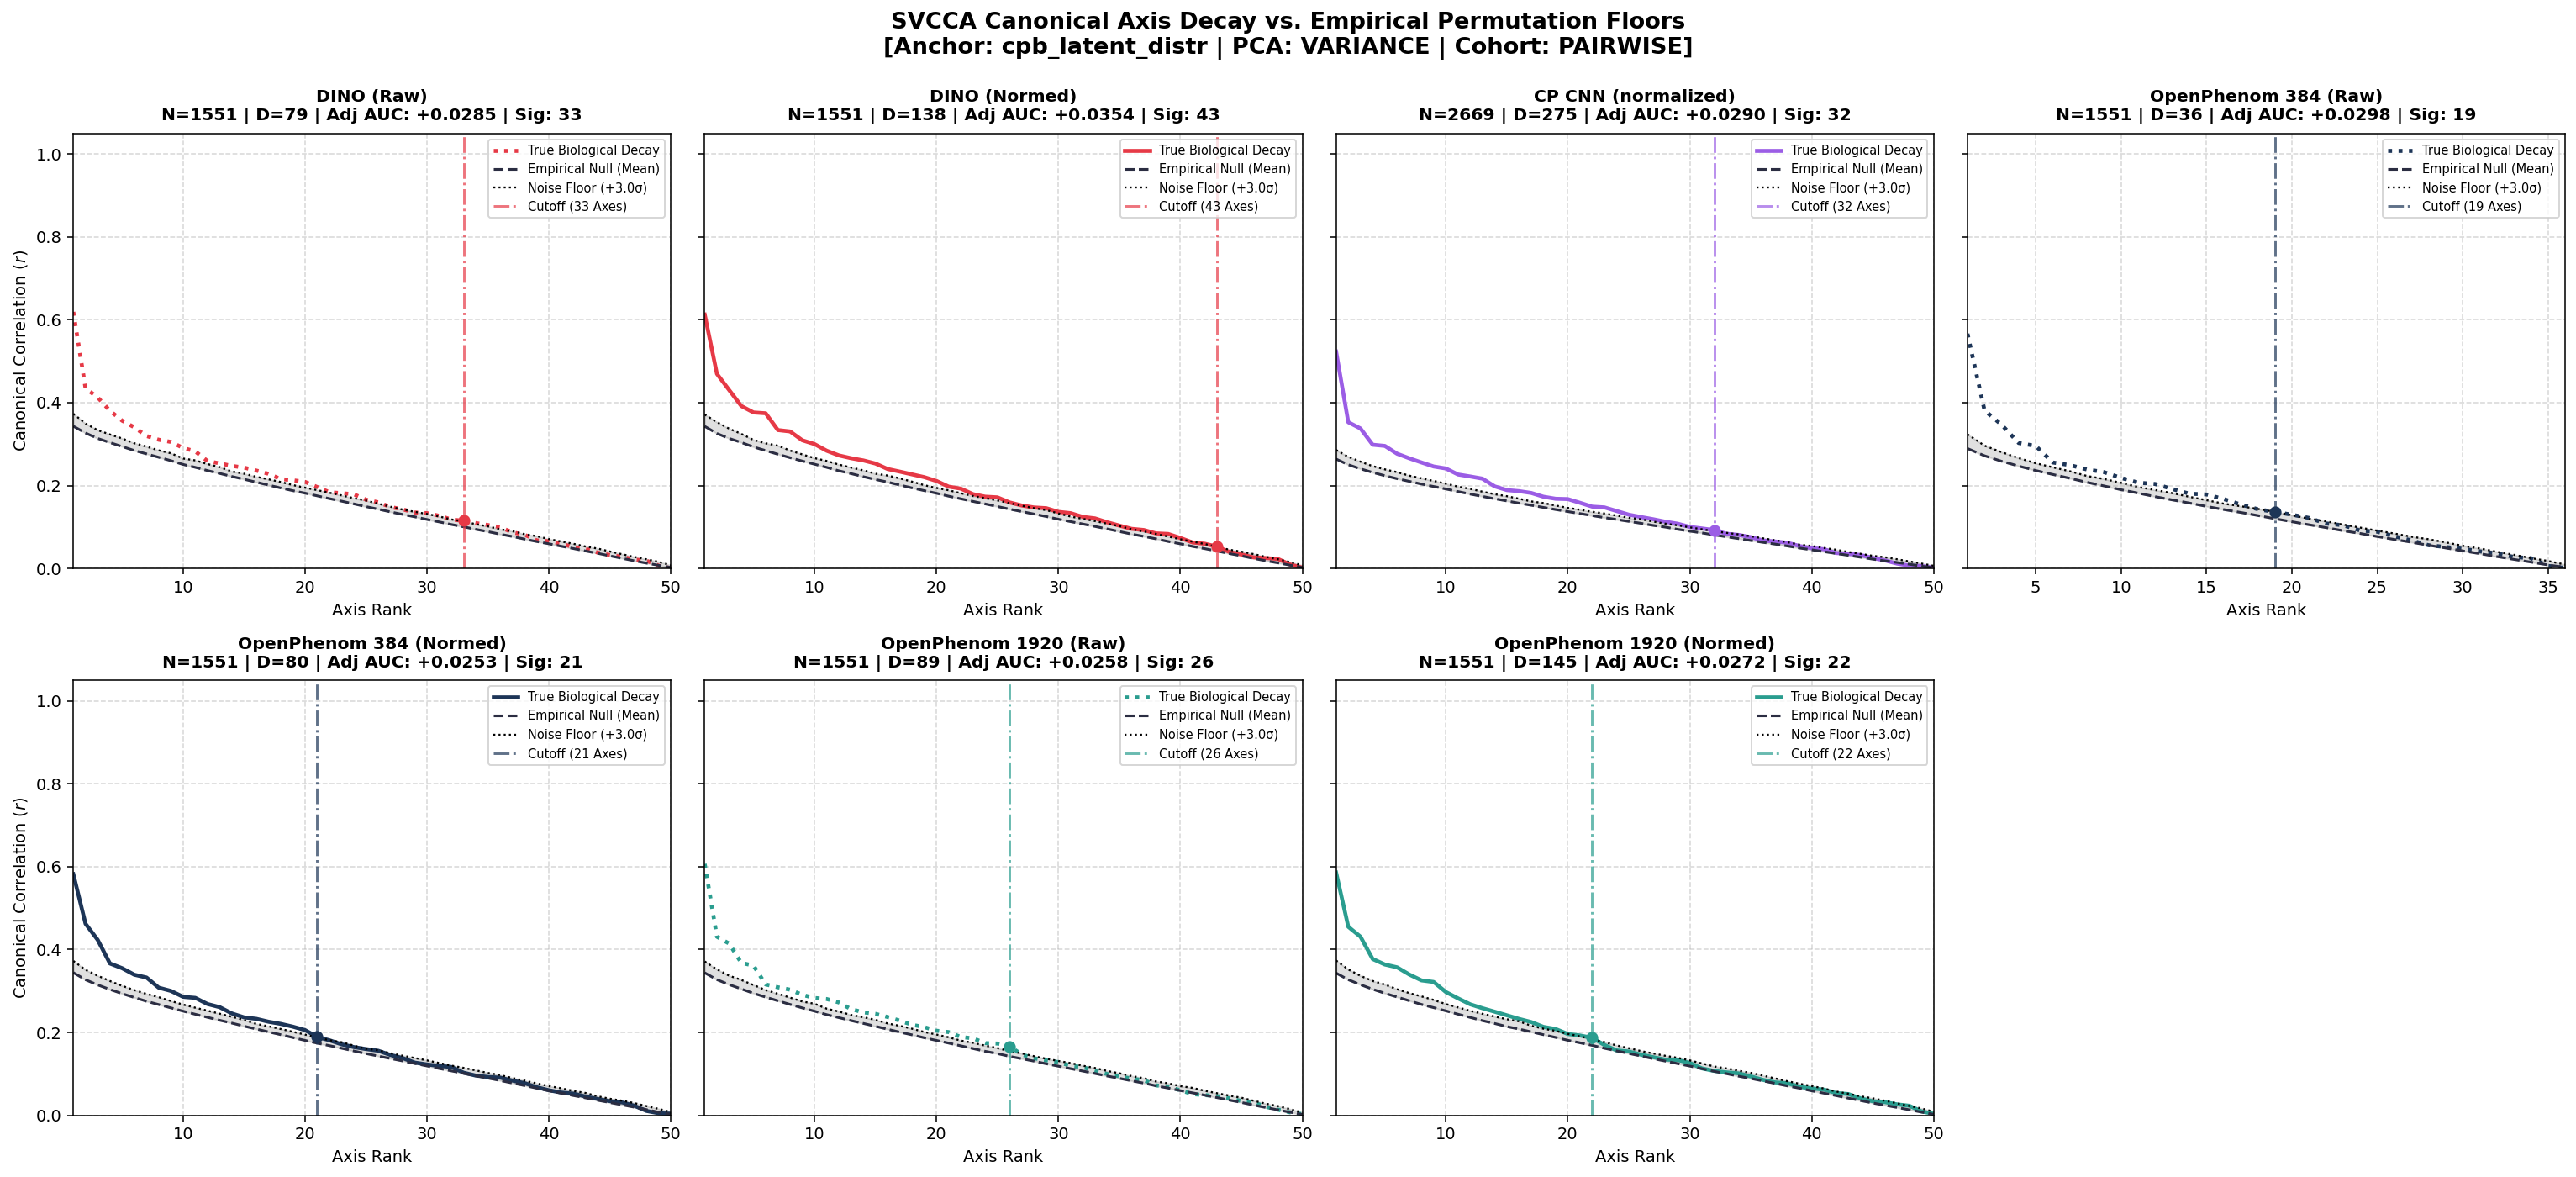

In [9]:
floor_label = (
    f"Noise Floor (+{STAT_THRESHOLD_SIGMA}σ)"
    if STAT_THRESHOLD_MODE == "std"
    else f"{STAT_THRESHOLD_PERCENTILE}th % Floor"
)

print("\nGenerating Multi-Panel SVCCA Decay Grid with Configured Noise Thresholds...")
plot_svcca_floor_grid(
    leaderboard_df,
    decay_curves,
    null_curves,
    cutoff_curves,
    floor_label,
    f"[Anchor: {TRANSCRIPTOMIC_SOURCE} | PCA: {PCA_MODE.upper()} | Cohort: {COHORT_STRATEGY.upper()}]",
    max_axes=MAX_EVAL_AXES,
)

## Part 2 - What biology do the shared axes capture? (Chemical Checker, structure and morphology)

For the top-ranked model, compounds are scored on the top canonical axes (optionally unmixed), and each axis is decoded:

* **Genes and pathways.** Which genes follow the axis (raw DRUG-seq, 5,000 most variable genes), which Hallmark pathways
  they enrich (GSEA and over-representation analysis), and how *pure* the axis is (Part 3 explains the metrics).
* **Chemistry.** The drivers - compounds scoring above mean + 2 SD - are compared with random compounds in Chemical
  Checker space (bioactivity) and by 2D structure (ECFP4 Tanimoto similarity). Together these tell a congeneric series
  from different scaffolds converging on one cellular state.
* **Morphology check.** Do the drivers also look alike in the images? Profiles are mean-centered before cosine
  similarity is computed (otherwise embeddings pointing in a common direction look similar whatever the compound does).
  The driver closest to the group's centroid is reported as its *medoid*.
* A figure with the gene volcano plot next to the morphology similarity distributions.

> ⚠️ Same caveats as Step 4.1 Part 3: only the positive end of each axis is examined; Mann-Whitney p-values on pairwise
> similarities are optimistic because the pairs are not independent; IC50 units in the ChEMBL fallback annotation are not
> checked.

### 2.1 Configuration and top-ranked model
`UNMIXING_METHOD` chooses how the canonical axes are cut: `"none"` (raw SVCCA axes), `"varimax"`, `"fastica"` or
`"hybrid"` (FastICA, then Varimax). The saved run used `"fastica"`.

In [10]:
NUM_AXES_TO_ANALYZE = 10  # Top biological axes to decode
UNMIXING_METHOD = "fastica"  # "none" | "varimax" | "fastica" | "hybrid"

CHEMCHECKER_URI = (
    "gs://calico-reference-embeddings/embeddings/Chemical_Checker_Embeddings/JUMP_CP_Global_Signatures_full.parquet"
)
# Same files as Step 4.2 Part 3, so a cache downloaded there is reused
LOCAL_CC_CACHE = "cached_chemchecker_embeddings.parquet"

RAW_GENES_URI = "gs://calico-reference-embeddings/embeddings/Novartis_DRUGseq_expression_data/Novartis_U2OS_Dose_Time_Signatures.parquet"
LOCAL_RAW_GENES_CACHE = "cached_drugseq_raw_genes.parquet"

# Standardized SMILES of the JUMP compounds, for the 2D structural similarity of the drivers
SMILES_URI = "gs://calico-reference-embeddings/Annotations_from_Roman/Bayer_data_harmonized/annotations_from_Roman/JUMP_CP_compound_metadata_with_SMILES_standard.csv"
LOCAL_SMILES_LOOKUP = "jump_smiles_standard_lookup.parquet"

top_model_name = leaderboard_df.iloc[0]["Model / Processing"]
top_score = leaderboard_df.iloc[0]["SVCCA Adj. AUC"]
sig_axes_known = int(leaderboard_df.iloc[0]["Significant Axes"])

print("=" * 95)
print(f"🏆 DECODING WINNING MODEL: [{top_model_name}]")
print(f"📊 Benchmark Score (SVCCA Adj. AUC): {top_score:+.4f} | Statistically Verified Dimensions: {sig_axes_known}")
print(f"🧬 Transcriptomic Alignment Anchor: {TRANSCRIPTOMIC_SOURCE} ({LOCAL_RNA_CACHE})")
print(f"🎛️ Subspace Unmixing Engine: {UNMIXING_METHOD.upper()}")
print("🔬 Bioactivity Reference: Chemical Checker 3,200D Embeddings")
print(f"🎯 Decoding Horizon: Top {NUM_AXES_TO_ANALYZE} Biological Dimensions")
print("=" * 95)

🏆 DECODING WINNING MODEL: [DINO (Normed)]
📊 Benchmark Score (SVCCA Adj. AUC): +0.0354 | Statistically Verified Dimensions: 43
🧬 Transcriptomic Alignment Anchor: cpb_latent_distr (cached_cpb_latent_anchor.parquet)
🎛️ Subspace Unmixing Engine: FASTICA
🔬 Bioactivity Reference: Chemical Checker 3,200D Embeddings
🎯 Decoding Horizon: Top 10 Biological Dimensions


### 2.2 Canonical axes of the top model
The top model is aligned with the anchor exactly as in Part 1 (same compounds, same PCA setting). Every compound is scored on
the top axes, which are then unmixed with `UNMIXING_METHOD`. The mean-centered, unit-length morphology profiles are kept
for the morphology check in 2.6.

In [11]:
winner_cache = cached_filepaths[top_model_name]

X_morph, Y_rna, active_inchikeys = load_overlap_pair(winner_cache, LOCAL_RNA_CACHE, target_keys=common_keys_set)
X_morph_proc = reduce_dimensions(
    X_morph, mode=PCA_MODE, var_threshold=PCA_VARIANCE_THRESHOLD, fixed_dims=PCA_FIXED_DIMS
)

# Mean-centered, unit-length morphology (cosine similarity = Pearson correlation), looked up by compound
X_morph_normed = centered_unit_vectors(X_morph, device=device)
morph_key_to_idx = {k: i for i, k in enumerate(active_inchikeys)}
del X_morph
release_memory()

N_samples = len(active_inchikeys)
k_decomp = min(50, int(N_samples * 0.8), X_morph_proc.shape[1], Y_rna.shape[1])

X_m = torch.tensor(X_morph_proc, device=device, dtype=torch.float64)
Y_r = torch.tensor(Y_rna, device=device, dtype=torch.float64)
X_m = X_m - X_m.mean(dim=0)
Y_r = Y_r - Y_r.mean(dim=0)

Qa = get_exact_subspace_basis(X_m, k_decomp)
Qb = get_exact_subspace_basis(Y_r, k_decomp)

cross_cov = torch.matmul(Qa.T, Qb)
U, S, Vt = torch.linalg.svd(cross_cov, full_matrices=False)
U, Vt = svd_flip_torch(U, Vt)

n_axes_actual = min(NUM_AXES_TO_ANALYZE, U.shape[1])
canonical_scores = torch.matmul(Qa, U[:, :n_axes_actual]).cpu().numpy()
del X_m, Y_r, Qa, Qb, cross_cov, X_morph_proc, Y_rna
release_memory()

# Optional unmixing: same subspace, cut into more interpretable axes
bio_canonical_scores, axis_prefix = unmix_scores(canonical_scores, UNMIXING_METHOD)
canonical_r = S[:n_axes_actual].cpu().numpy() if UNMIXING_METHOD == "none" else None

axis_cols = [f"{axis_prefix}_{i + 1}" for i in range(n_axes_actual)]
bio_scores_df = pd.DataFrame(bio_canonical_scores, columns=axis_cols)
bio_scores_df[MERGE_KEY] = active_inchikeys

print(
    f"✅ Projection & Disentanglement Complete: {N_samples:,} compounds mapped to {n_axes_actual} {axis_prefix} dimensions."
)

🔄 Applying FastICA: Decomposing into statistically independent biological programs...
✅ Projection & Disentanglement Complete: 1,551 compounds mapped to 10 ICA_Axis dimensions.


### 2.3 Gene-level DRUG-seq and Chemical Checker
Raw DRUG-seq signatures are pooled per compound (max-absolute pooling) and reduced to the 5,000 most variable genes; the
Chemical Checker table is reduced to the scored compounds (all-zero signatures dropped), and the standardized SMILES table
is prepared. Only matching rows are read from disk.

In [12]:
conn = duckdb.connect()
conn.register("active_compounds_view", pd.DataFrame({MERGE_KEY: active_inchikeys}))

# Raw genes for GSEA and volcano decoding
if not cache_from_gcs(RAW_GENES_URI, LOCAL_RAW_GENES_CACHE, "raw DRUG-seq genes"):
    raise RuntimeError(f"Could not download {RAW_GENES_URI}")

raw_key = resolve_key_column([f.name for f in pq.read_schema(LOCAL_RAW_GENES_CACHE)])
print(f"📂 Streaming raw gene expression from disk for {N_samples:,} compounds...")
raw_genes_df = conn.execute(f"""
    SELECT * FROM read_parquet('{LOCAL_RAW_GENES_CACHE}')
    WHERE {raw_key} IN (SELECT {MERGE_KEY} FROM active_compounds_view)
""").df()
raw_genes_df = standardize_inchikey_column(raw_genes_df, MERGE_KEY)

all_ensembl_cols = [c for c in raw_genes_df.columns if c.startswith("ENSG")]
if not all_ensembl_cols:
    all_ensembl_cols = [
        c
        for c in raw_genes_df.select_dtypes(include=[np.number]).columns
        if c not in [MERGE_KEY, "pubchem_cid", "pert_time_h", "pert_dose_uM"]
    ]

drugseq_pooled_genes = max_absolute_pooling(raw_genes_df, MERGE_KEY, all_ensembl_cols)
del raw_genes_df
release_memory()

# Pre-filter to the 5,000 most variable genes
gene_variances = drugseq_pooled_genes[all_ensembl_cols].var(axis=0)
active_ensembl_genes = gene_variances.nlargest(min(5000, len(all_ensembl_cols))).index.tolist()
drugseq_pooled_genes = drugseq_pooled_genes[[MERGE_KEY] + active_ensembl_genes].copy()
print(f"  ↳ Retained Top {len(active_ensembl_genes):,} dynamic Ensembl genes for downstream decoding.")

# Chemical Checker
if not cache_from_gcs(CHEMCHECKER_URI, LOCAL_CC_CACHE, "Chemical Checker"):
    raise RuntimeError(f"Could not download {CHEMCHECKER_URI}")

cc_key = resolve_key_column([f.name for f in pq.read_schema(LOCAL_CC_CACHE)])
print("📂 Streaming Chemical Checker 3,200D embeddings for active cohort...")
cc_df = conn.execute(f"""
    SELECT * FROM read_parquet('{LOCAL_CC_CACHE}')
    WHERE {cc_key} IN (SELECT {MERGE_KEY} FROM active_compounds_view)
""").df()
conn.close()

cc_df = standardize_inchikey_column(cc_df, MERGE_KEY)
cc_features = [
    c
    for c in cc_df.select_dtypes(include=[np.number]).columns
    if not c.startswith("Metadata_") and c not in [MERGE_KEY, "pubchem_cid"]
]

cc_matrix = np.nan_to_num(cc_df[cc_features].values.astype(np.float32), nan=0.0)
cc_df[cc_features] = cc_matrix

valid_mask = np.linalg.norm(cc_matrix, axis=1) > 1e-6
cc_df = cc_df[valid_mask].drop_duplicates(subset=[MERGE_KEY], keep="first").reset_index(drop=True)
del cc_matrix
release_memory()
print(f"✅ Chemical Checker subset loaded: {len(cc_df):,} compounds x {len(cc_features)} dimensions.")

# Standardized SMILES (built once from a CSV)
ensure_smiles_lookup(SMILES_URI, LOCAL_SMILES_LOOKUP)

📂 Streaming raw gene expression from disk for 1,551 compounds...


  ↳ Retained Top 5,000 dynamic Ensembl genes for downstream decoding.
📂 Streaming Chemical Checker 3,200D embeddings for active cohort...


INFO:biothings.client:querying 1-1000 ...


✅ Chemical Checker subset loaded: 1,551 compounds x 3200 dimensions.


### 2.4 Gene symbols
Ensembl gene IDs are translated to gene symbols with MyGene.info.

In [13]:
print(f"Querying MyGene for HGNC symbols across {len(active_ensembl_genes):,} Ensembl IDs...")
mg = mygene.MyGeneInfo()
clean_ensembl_ids = [g.split(".")[0] for g in active_ensembl_genes]
gene_info = mg.querymany(clean_ensembl_ids, scopes="ensembl.gene", fields="symbol", species="human", as_dataframe=False)

ensembl_to_symbol = {}
for h in gene_info:
    if "query" in h and "symbol" in h:
        ensembl_to_symbol[h["query"]] = h["symbol"]

print(f"✅ Successfully mapped {len(ensembl_to_symbol):,} of {len(active_ensembl_genes):,} Ensembl IDs.")

Querying MyGene for HGNC symbols across 5,000 Ensembl IDs...


INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


✅ Successfully mapped 4,656 of 5,000 Ensembl IDs.


### 2.5 Centre the gene matrix
Gene profiles of the scored compounds, centred once for all axes.

In [14]:
merged_all = pd.merge(bio_scores_df, drugseq_pooled_genes, on=MERGE_KEY, how="inner")
merged_all = merged_all.sort_values(by=MERGE_KEY, kind="stable").reset_index(drop=True)

if len(merged_all) == 0:
    raise RuntimeError("Zero overlap between projected compounds and raw gene expression data!")

clean_rna_matrix = np.nan_to_num(
    merged_all[active_ensembl_genes].values.astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0
)
all_genes_tensor = torch.tensor(clean_rna_matrix, device=device)
Y_c_genes = all_genes_tensor - all_genes_tensor.mean(dim=0)
var_Y_genes = torch.sum(Y_c_genes**2, dim=0)
del clean_rna_matrix, all_genes_tensor

### 2.6 Decode each axis
For each axis: the genes that follow it and its transcriptional purity; Hallmark GSEA and over-representation analysis;
driver similarity in Chemical Checker and by 2D structure; the morphology coherence of the drivers; the five top drivers
annotated through PubChem/ChEMBL; and a figure with the gene volcano plot next to the morphology similarity densities.


🎯 ICA_Axis_1 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ZNF559-ZNF177 (+0.18), GNG7 (+0.16), TMEM170B (+0.16), SELENOP (+0.15), HSPA1B (+0.15)
  ↳ Key Downregulated : ROBO4 (-0.18), NT5DC4 (-0.17), ZNF554 (-0.16), OSTM1 (-0.16), B3GNT5 (-0.15)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.18 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.214 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 2.0% (1/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • Myogenesis                                       | NES: +1.22 | FDR: 1.00e+00
     • Oxidative Phosphorylation                        | NES: +1.16 | FDR: 1.00e+00
     • Coagulation                                      | NES: +1.14 | FDR: 1.00e+00
     • Fatty Acid Metabolism                            | NES: +1.11 | FDR: 9.60e-01
     • Androgen Response                              

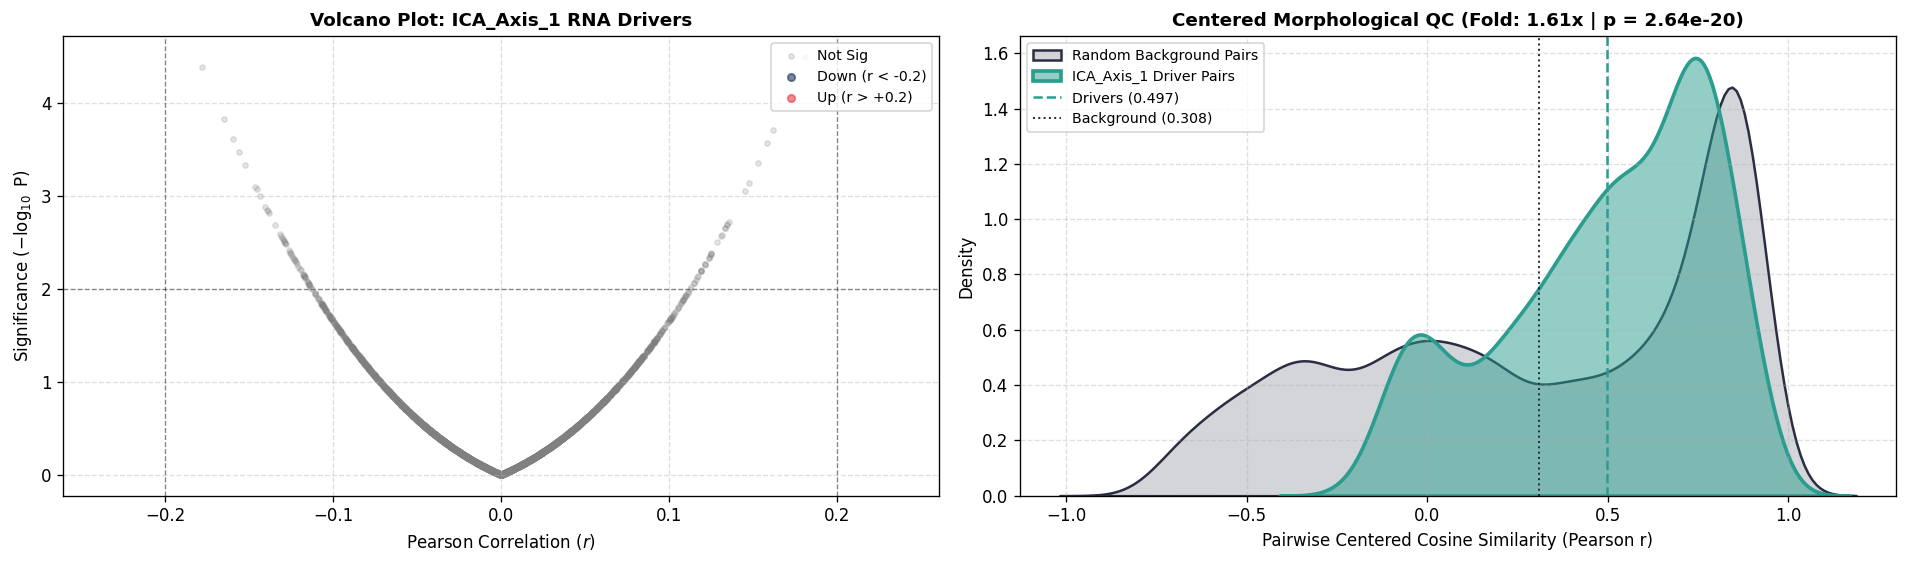


🎯 ICA_Axis_2 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : LOC102724428 (+0.18), SIRT5 (+0.17), ENSG00000188850 (+0.16), CPLX1 (+0.16), NEURL3 (+0.15)
  ↳ Key Downregulated : CRCT1 (-0.26), LOC101928994 (-0.23), JARID2-DT (-0.19), PTGES (-0.18), BZW1P2 (-0.18)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.53 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.218 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 0.0% (0/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • IL-2/STAT5 Signaling                             | NES: +1.45 | FDR: 6.09e-01
     • Unfolded Protein Response                        | NES: +1.29 | FDR: 8.42e-01
     • Hypoxia                                          | NES: +1.23 | FDR: 7.20e-01
     • mTORC1 Signaling                                 | NES: +1.12 | FDR: 9.28e-01
     • p53 Pathway                      

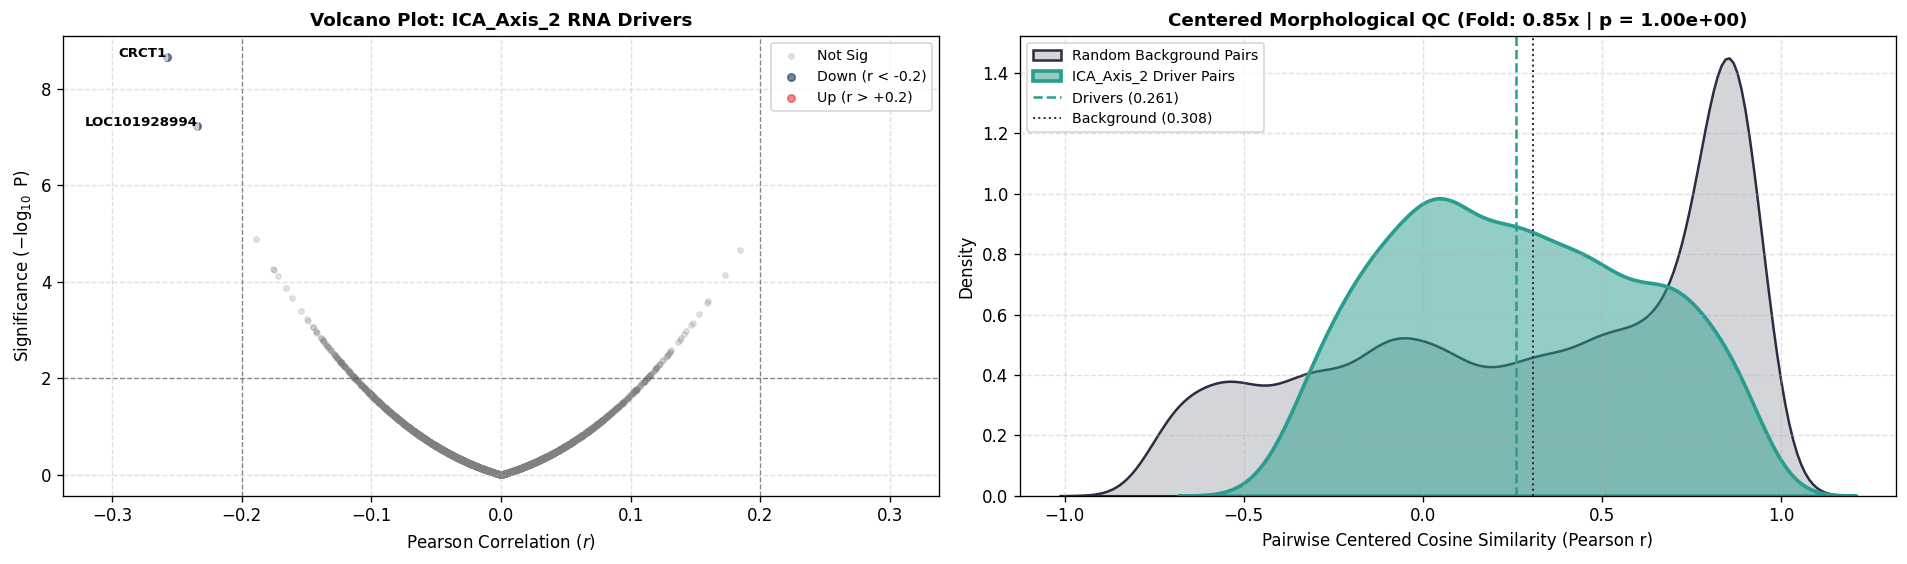


🎯 ICA_Axis_3 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : IGFL2-AS1 (+0.30), ZNF114 (+0.21), GABARAPL1 (+0.19), WIPI1 (+0.18), CEBPD (+0.17)
  ↳ Key Downregulated : RPS2P53 (-0.21), KRT75 (-0.20), CGB8 (-0.19), STRA6 (-0.18), ANKRD2 (-0.18)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.58 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.216 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 2.0% (1/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • IL-2/STAT5 Signaling                             | NES: +1.74 | FDR: 1.43e-01
     • Hypoxia                                          | NES: +1.58 | FDR: 2.94e-01
     • Androgen Response                                | NES: +1.57 | FDR: 2.09e-01
     • Cholesterol Homeostasis                          | NES: +1.53 | FDR: 2.09e-01
     • Apoptosis                                        | N

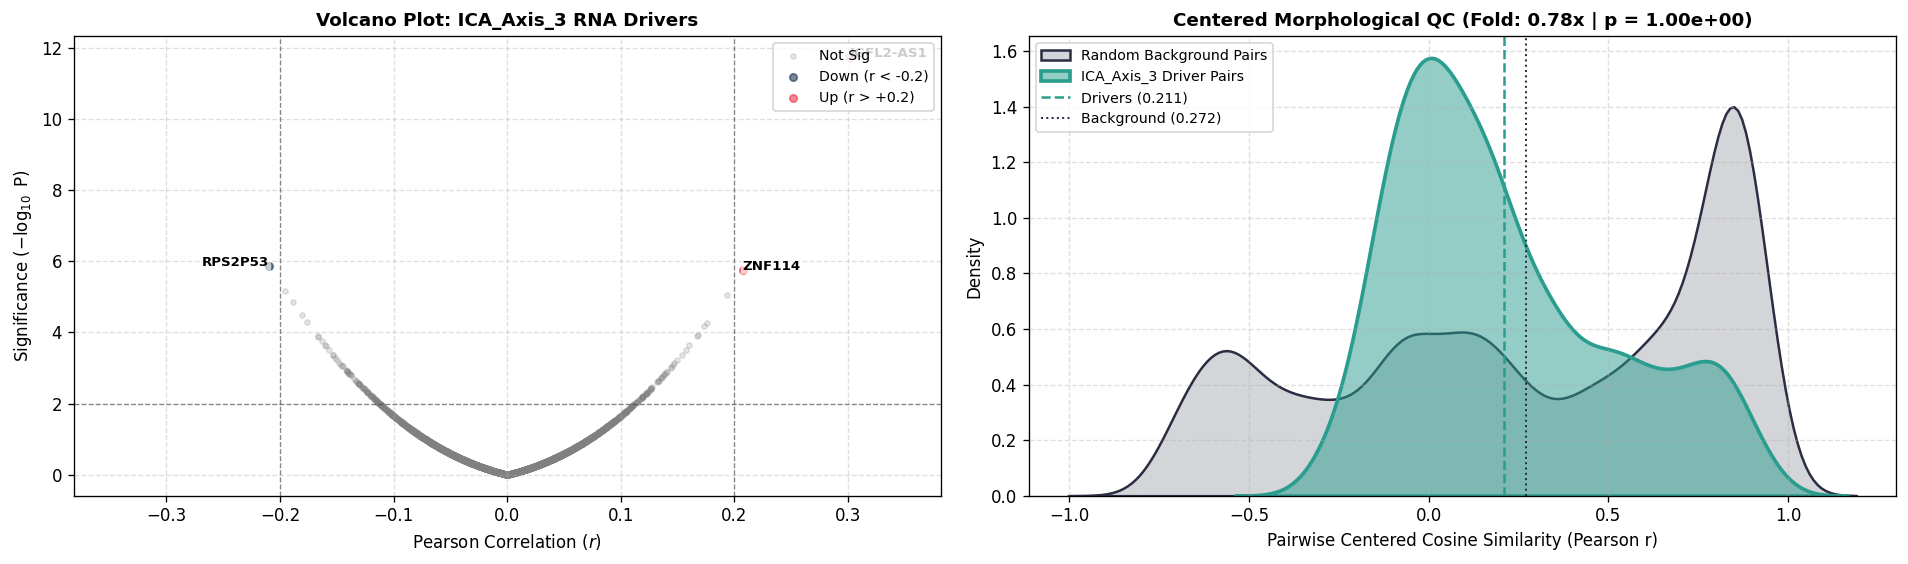


🎯 ICA_Axis_4 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ENSG00000258314 (+0.24), PLAC8 (+0.22), RARRES2 (+0.22), PSLNR (+0.22), IGFBP5 (+0.20)
  ↳ Key Downregulated : LOC124903825 (-0.25), KCNQ2 (-0.24), MIR7-3HG (-0.24), GAST (-0.24), ENSG00000286393 (-0.20)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  1.05 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.233 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 0.0% (0/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • KRAS Signaling Up                                | NES: +1.49 | FDR: 4.24e-01
     • UV Response Dn                                   | NES: +1.17 | FDR: 1.00e+00
     • Hypoxia                                          | NES: +1.05 | FDR: 1.00e+00
     • IL-6/JAK/STAT3 Signaling                         | NES: +1.02 | FDR: 1.00e+00
     • TNF-alpha Signaling via NF-kB  

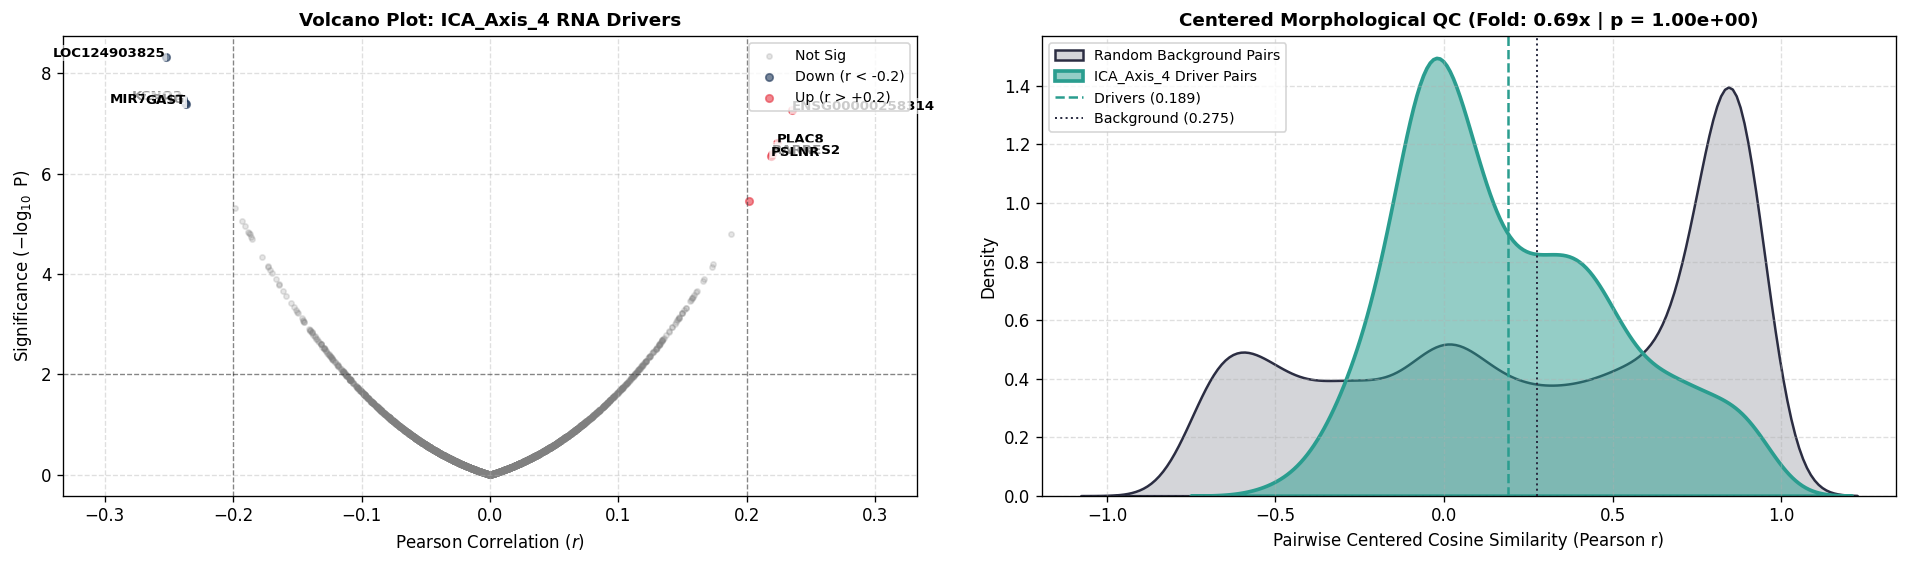


🎯 ICA_Axis_5 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ZNF114 (+0.22), IGFL2-AS1 (+0.22), CEBPD (+0.21), FBXO32 (+0.19), HTR3A (+0.18)
  ↳ Key Downregulated : RPL9P21 (-0.28), CMYA5 (-0.25), ERAP1 (-0.20), ENSG00000269693 (-0.18), TASP1 (-0.18)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  1.20 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.231 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 4.0% (2/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • TNF-alpha Signaling via NF-kB                    | NES: +1.99 | FDR: 0.00e+00
     • p53 Pathway                                      | NES: +1.77 | FDR: 3.64e-02
     • Unfolded Protein Response                        | NES: +1.73 | FDR: 4.10e-02
     • heme Metabolism                                  | NES: +1.71 | FDR: 4.20e-02
     • Apoptosis                                    

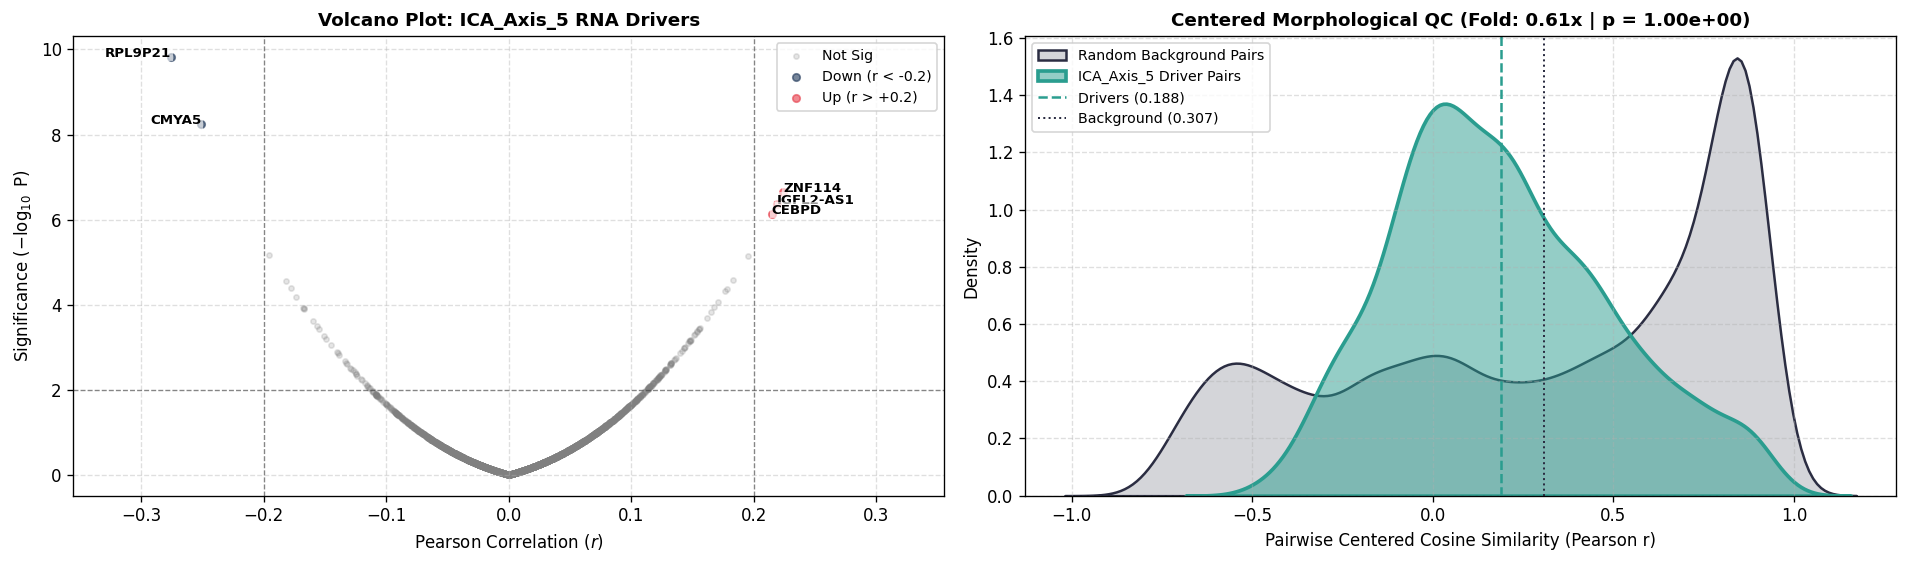


🎯 ICA_Axis_6 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ENSG00000258314 (+0.21), PSLNR (+0.21), MOB3B (+0.20), EDN2 (+0.19), PDLIM1 (+0.19)
  ↳ Key Downregulated : MIR7-3HG (-0.32), FOS (-0.29), LOC124903825 (-0.28), MMP10 (-0.28), IER2 (-0.27)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  1.20 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.239 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 0.0% (0/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • E2F Targets                                      | NES: +1.60 | FDR: 7.89e-02
     • G2-M Checkpoint                                  | NES: +1.31 | FDR: 2.55e-01
     • Apical Surface                                   | NES: +0.97 | FDR: 8.47e-01
     • Myogenesis                                       | NES: +0.87 | FDR: 8.66e-01
     • Spermatogenesis                               

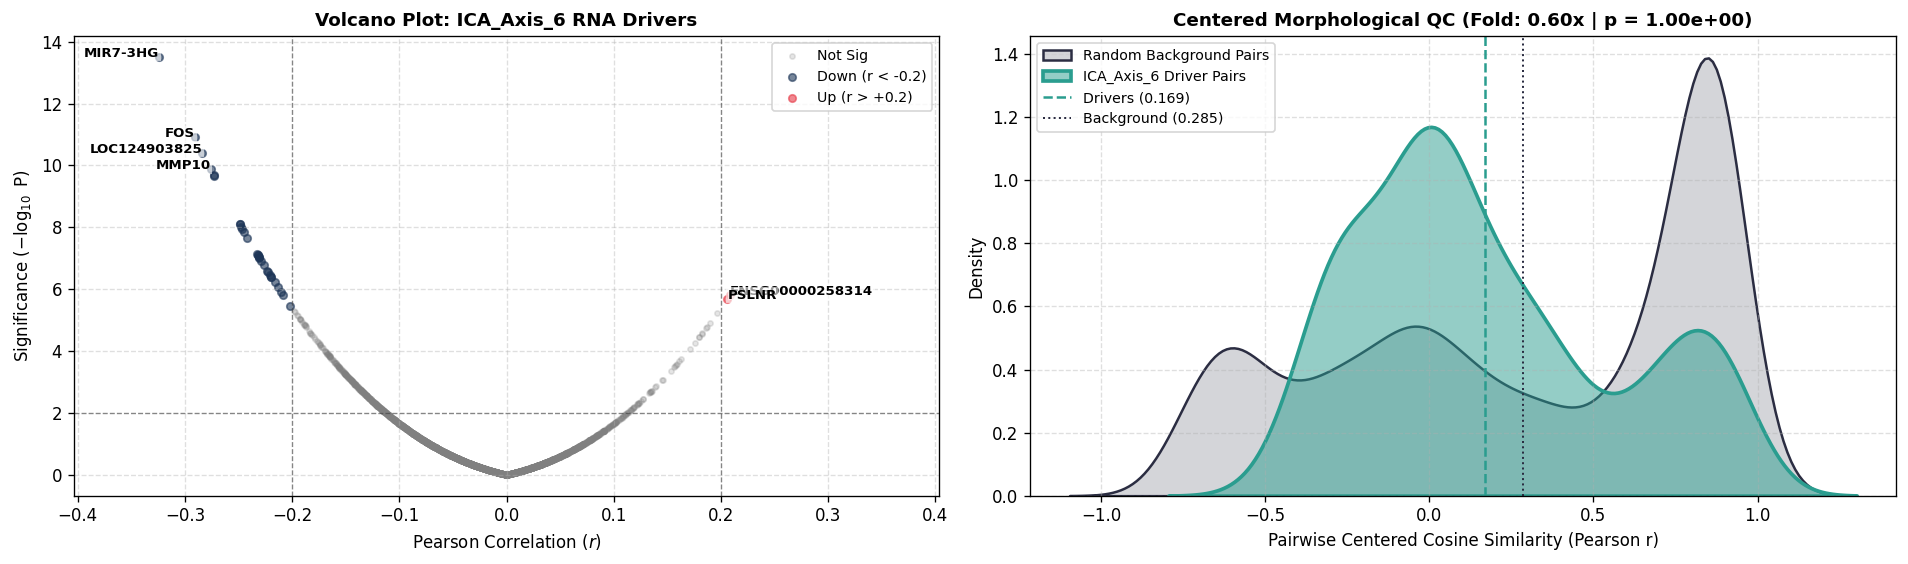


🎯 ICA_Axis_7 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : GTPBP10 (+0.16), ZNF438 (+0.15), UFSP2 (+0.14), DTWD1 (+0.13), CAMLG (+0.13)
  ↳ Key Downregulated : ENSG00000273141 (-0.19), LINC01766 (-0.18), RN7SKP187 (-0.17), RN7SKP255 (-0.17), C11orf96 (-0.16)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.19 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.214 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 0.0% (0/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • UV Response Dn                                   | NES: +1.53 | FDR: 5.03e-01
     • Spermatogenesis                                  | NES: +1.52 | FDR: 2.61e-01
     • Oxidative Phosphorylation                        | NES: +1.46 | FDR: 2.45e-01
     • TGF-beta Signaling                               | NES: +1.39 | FDR: 2.64e-01
     • Protein Secretion                  

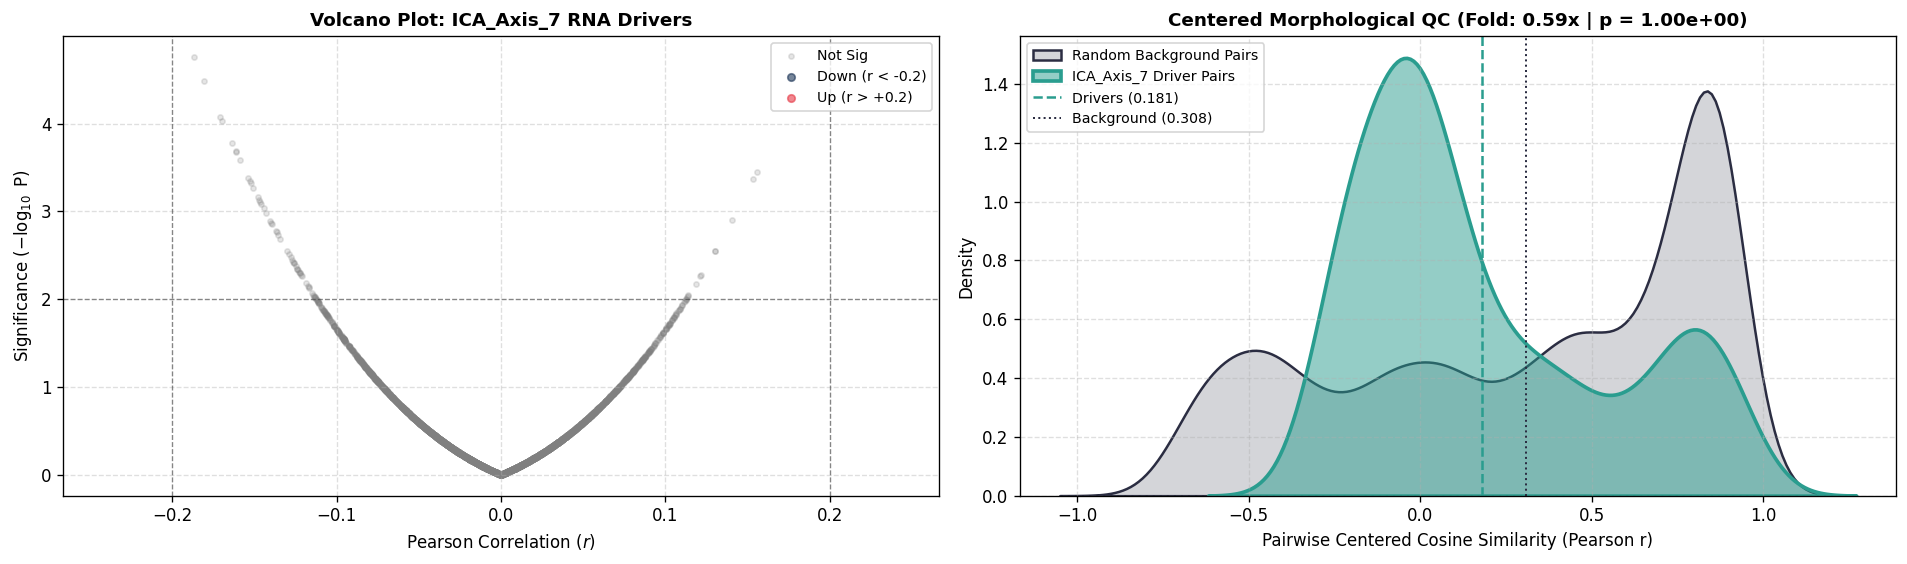


🎯 ICA_Axis_8 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ZNF571 (+0.27), ENSG00000287190 (+0.24), PURPL (+0.24), BMP2K-DT (+0.23), CPD (+0.23)
  ↳ Key Downregulated : SEMA4D (-0.20), BMAL1 (-0.18), TMEM37 (-0.17), ENSG00000243155 (-0.17), GPRC5C (-0.17)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.36 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.209 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 4.0% (2/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • Epithelial Mesenchymal Transition                | NES: +2.24 | FDR: 0.00e+00
     • TNF-alpha Signaling via NF-kB                    | NES: +2.16 | FDR: 0.00e+00
     • Estrogen Response Late                           | NES: +1.97 | FDR: 8.15e-03
     • UV Response Up                                   | NES: +1.67 | FDR: 1.04e-01
     • p53 Pathway                           

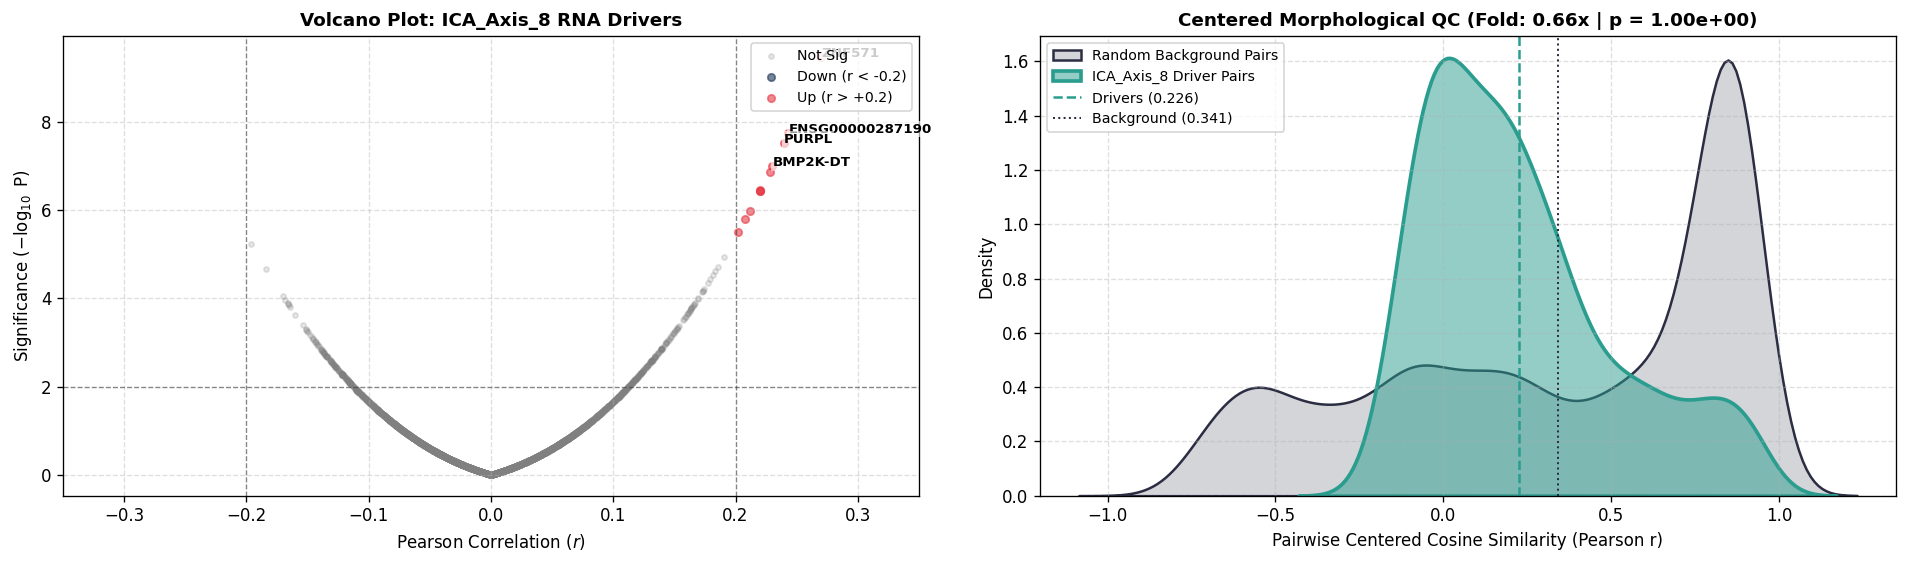


🎯 ICA_Axis_9 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : ESM1 (+0.24), MYCT1 (+0.21), NMRAL2P (+0.21), LINC00520 (+0.20), CRCT1 (+0.20)
  ↳ Key Downregulated : FOXO6 (-0.16), PSLNR (-0.16), PID1 (-0.16), RAB7B (-0.16), WFDC21P (-0.15)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.48 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.221 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 2.0% (1/50) [✅ Clean]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • TNF-alpha Signaling via NF-kB                    | NES: +1.90 | FDR: 1.00e-02
     • KRAS Signaling Up                                | NES: +1.76 | FDR: 3.00e-02
     • Inflammatory Response                            | NES: +1.74 | FDR: 3.00e-02
     • p53 Pathway                                      | NES: +1.72 | FDR: 2.63e-02
     • Allograft Rejection                              | NES: +

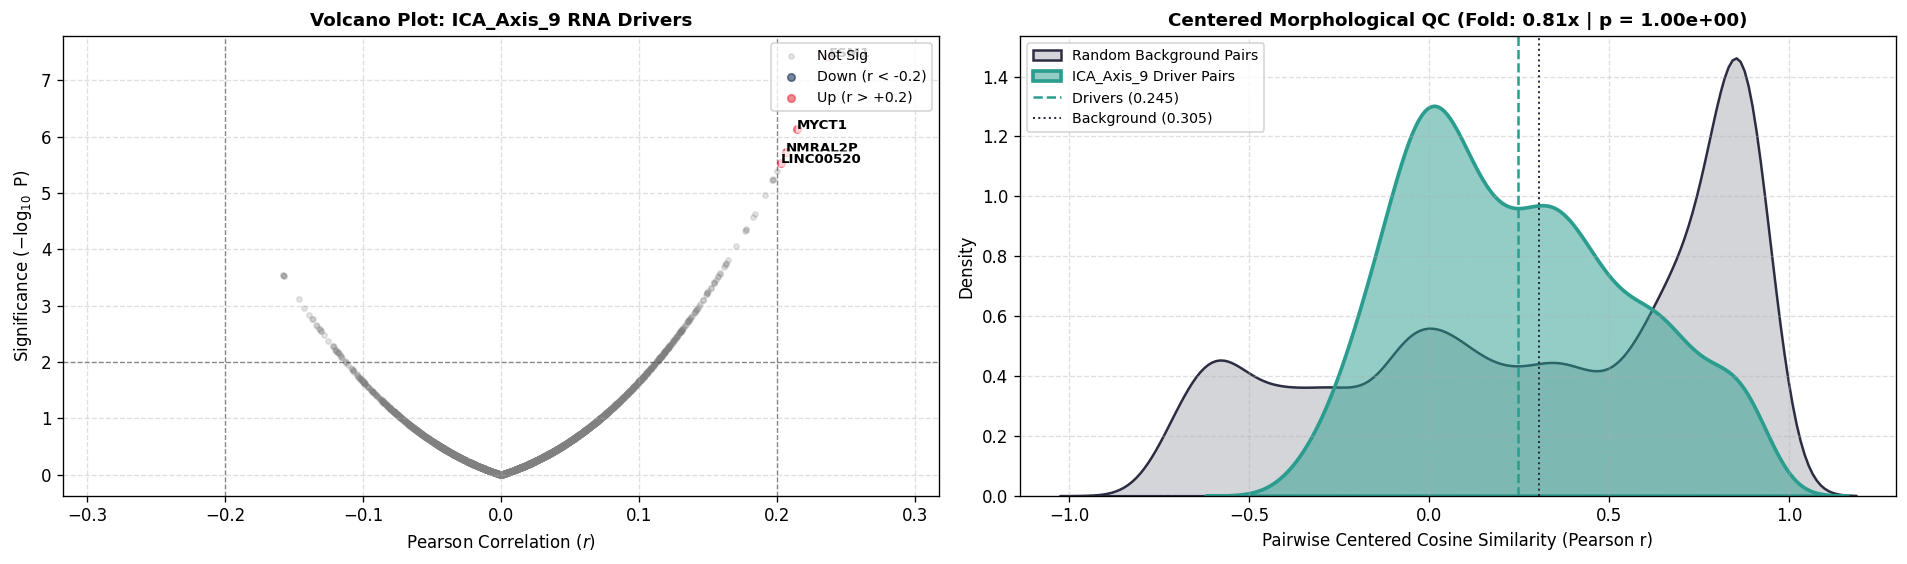


🎯 ICA_Axis_10 | Subspace Alignment: FASTICA | ✅ STATISTICALLY SIGNIFICANT (p < 0.05)
🧬 TRANSCRIPTIONAL SIGNATURE:
  ↳ Key Upregulated   : KANK4 (+0.29), CXCL8 (+0.25), HK2 (+0.23), MAP3K8 (+0.23), ELOVL4 (+0.23)
  ↳ Key Downregulated : BIRC7 (-0.23), LDLRAD4 (-0.21), WNT5B (-0.19), FOXS1 (-0.18), ENSG00000226472 (-0.17)

  🧼 Transcriptional Purity Profile:
     • Loading Kurtosis (κ)      :  0.70 (Target: > 6.0) [⚠️ Diffuse]
     • Hoyer Sparsity Index      : 0.227 (Target: > 0.40) [⚠️ Dense]
     • Pan-Stress Contamination  : 6.0% (3/50) [⚠️ Stressed]

  🟢 Top Positively Enriched Hallmarks (GSEA):
     • TNF-alpha Signaling via NF-kB                    | NES: +2.17 | FDR: 0.00e+00
     • Apoptosis                                        | NES: +1.93 | FDR: 0.00e+00
     • mTORC1 Signaling                                 | NES: +1.91 | FDR: 1.67e-03
     • IL-2/STAT5 Signaling                             | NES: +1.86 | FDR: 1.25e-03
     • UV Response Up                                

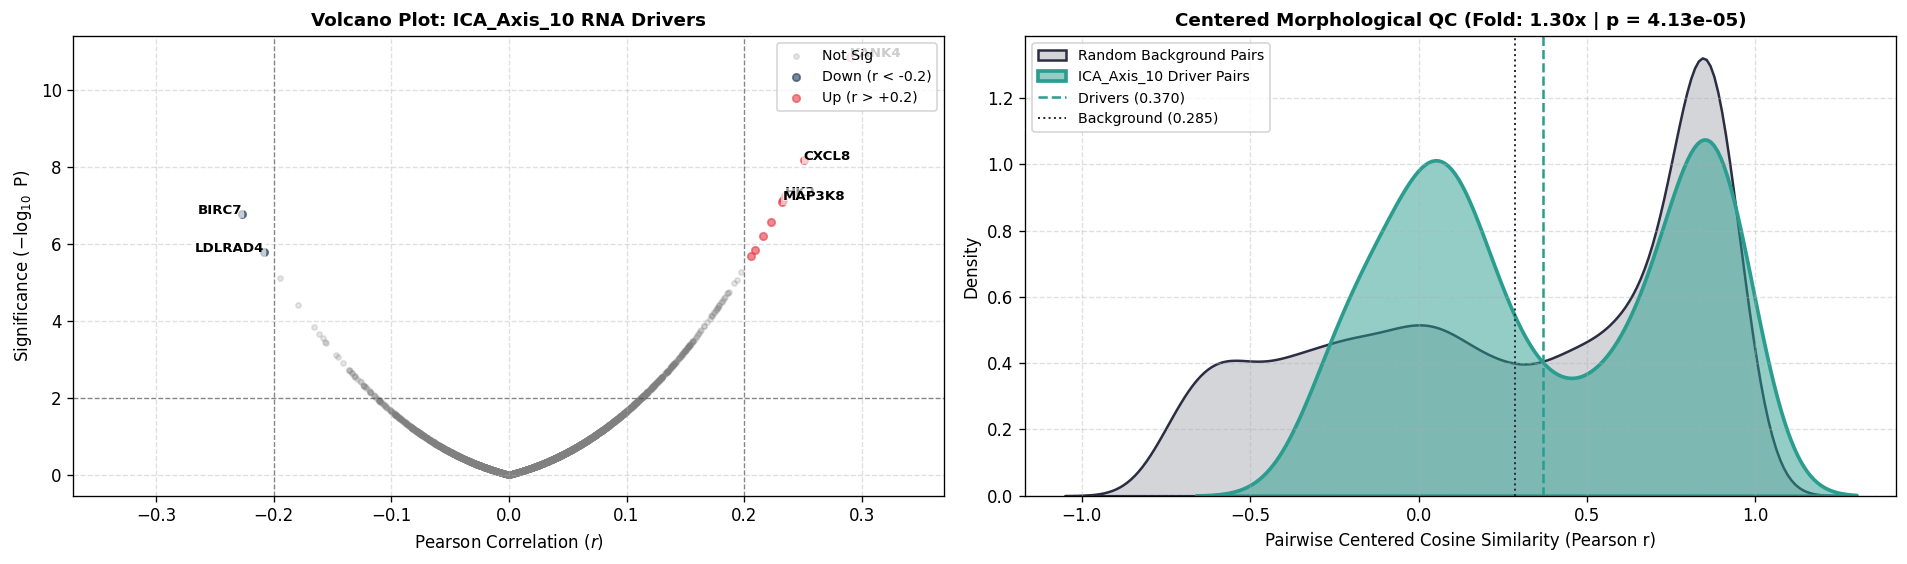


🏁 FULL UNMIXED DECODING (FASTICA) & MULTIMODAL QC COMPLETE


In [15]:
for axis_idx in range(n_axes_actual):
    axis_name = f"{axis_prefix}_{axis_idx + 1}"
    is_sig_tag = (
        "✅ STATISTICALLY SIGNIFICANT (p < 0.05)" if (axis_idx + 1) <= sig_axes_known else "⚠️ NOISE FLOOR BOUNDARY"
    )

    print("\n" + "=" * 95)
    if canonical_r is not None:
        print(f"🎯 {axis_name} | Canonical Correlation ($r$): {canonical_r[axis_idx]:.4f} | {is_sig_tag}")
    else:
        print(f"🎯 {axis_name} | Subspace Alignment: {UNMIXING_METHOD.upper()} | {is_sig_tag}")
    print("=" * 95)

    # Part A: genes and pathways that follow the axis, and how pure the axis is
    gene_df = gene_axis_statistics(
        merged_all[axis_name].values, Y_c_genes, var_Y_genes, active_ensembl_genes, ensembl_to_symbol
    )
    rnk_input = rank_genes(gene_df, "T_Stat")
    print_top_genes(
        gene_df.sort_values("Correlation", ascending=False).head(5),
        gene_df.sort_values("Correlation", ascending=True).head(5),
    )
    print_axis_purity(gene_df)
    print_gsea(
        rnk_input,
        "MSigDB_Hallmark_2020",
        "🟢 Top Positively Enriched Hallmarks (GSEA):",
        "🔴 Top Negatively Enriched Hallmarks (GSEA):",
        term_width=48,
    )
    print_ora(rnk_input)

    # Part B: are the driver compounds alike in bioactivity and in 2D structure, and in morphology?
    top_drivers = report_driver_chemistry(bio_scores_df, axis_name, cc_df, cc_features, MERGE_KEY, LOCAL_SMILES_LOOKUP)
    if len(top_drivers) < 5:
        continue
    coherence = report_morphology_coherence(top_drivers[MERGE_KEY].tolist(), X_morph_normed, morph_key_to_idx)
    print_driver_annotations(top_drivers, axis_name, MERGE_KEY)

    # Part C: volcano plot of the gene statistics next to the morphology coherence of the drivers
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8), dpi=120)
    plot_volcano(gene_df, f"Volcano Plot: {axis_name} RNA Drivers", title_fontsize=11, ax=ax1)
    plot_morphology_coherence(coherence, axis_name, ax2)
    plt.tight_layout()
    plt.show()
    release_memory()

print("\n" + "=" * 95)
print(f"🏁 FULL UNMIXED DECODING ({UNMIXING_METHOD.upper()}) & MULTIMODAL QC COMPLETE")
print("=" * 95)

## Part 3 - How pure are the axes?

A useful axis should be carried by a small, coherent set of genes and should not simply track generic cell stress. For
every axis the sweep reports

* **Kurtosis (κ)** of the gene statistics: high = a few genes dominate;
* **Hoyer sparsity**: 0 = all genes contribute equally, 1 = a single gene does;
* **Pan-stress %**: share of the 50 most positively correlated genes that belong to a generic stress panel (HMOX1, DDIT3,
  CDKN1A, GADD45A, ATF3, ATF4, HSPA1A/B, FOS, JUN, EGR1, IER3, BBC3);
* **Total-signal |r|**: correlation of the axis with the sum of a compound's expression changes (a crude measure of how
  strongly the compound perturbs cells overall - not sequencing depth).

*Pristine* needs κ ≥ 5, Hoyer ≥ 0.38, stress < 6% and total-signal |r| < 0.25; *Stressed / Artifact* means stress ≥ 14%
(or a cell-count correlation above 0.45 when cell counts are available). Everything else is *Mixed*. These cut-offs are
heuristics chosen for this analysis.

> **Fix applied.** In the draft, an axis could be called "Pristine" even if it tracked the cell count; now it cannot.

🧼 RUNNING FULL TRANSCRIPTIONAL PURITY SWEEP ACROSS ALL 10 AXES
   ↳ Detected Subspace Format: ICA
       Axis Kurtosis (κ) Hoyer Sparsity Pan-Stress % Read Depth |r| Cell Count |r|              Top 3 Upregulated Genes     Quality Verdict
 ICA_Axis_6         1.20          0.239         0.0%           0.11           None        ENSG00000258314, PSLNR, MOB3B ⚠️ Mixed / Moderate
 ICA_Axis_5         1.20          0.231         4.0%           0.04           None             ZNF114, IGFL2-AS1, CEBPD ⚠️ Mixed / Moderate
 ICA_Axis_4         1.05          0.233         0.0%           0.01           None      ENSG00000258314, PLAC8, RARRES2 ⚠️ Mixed / Moderate
ICA_Axis_10         0.70          0.227         6.0%           0.08           None                    KANK4, CXCL8, HK2 ⚠️ Mixed / Moderate
 ICA_Axis_3         0.58          0.216         2.0%           0.01           None         IGFL2-AS1, ZNF114, GABARAPL1 ⚠️ Mixed / Moderate
 ICA_Axis_2         0.53          0.218         0.0%          

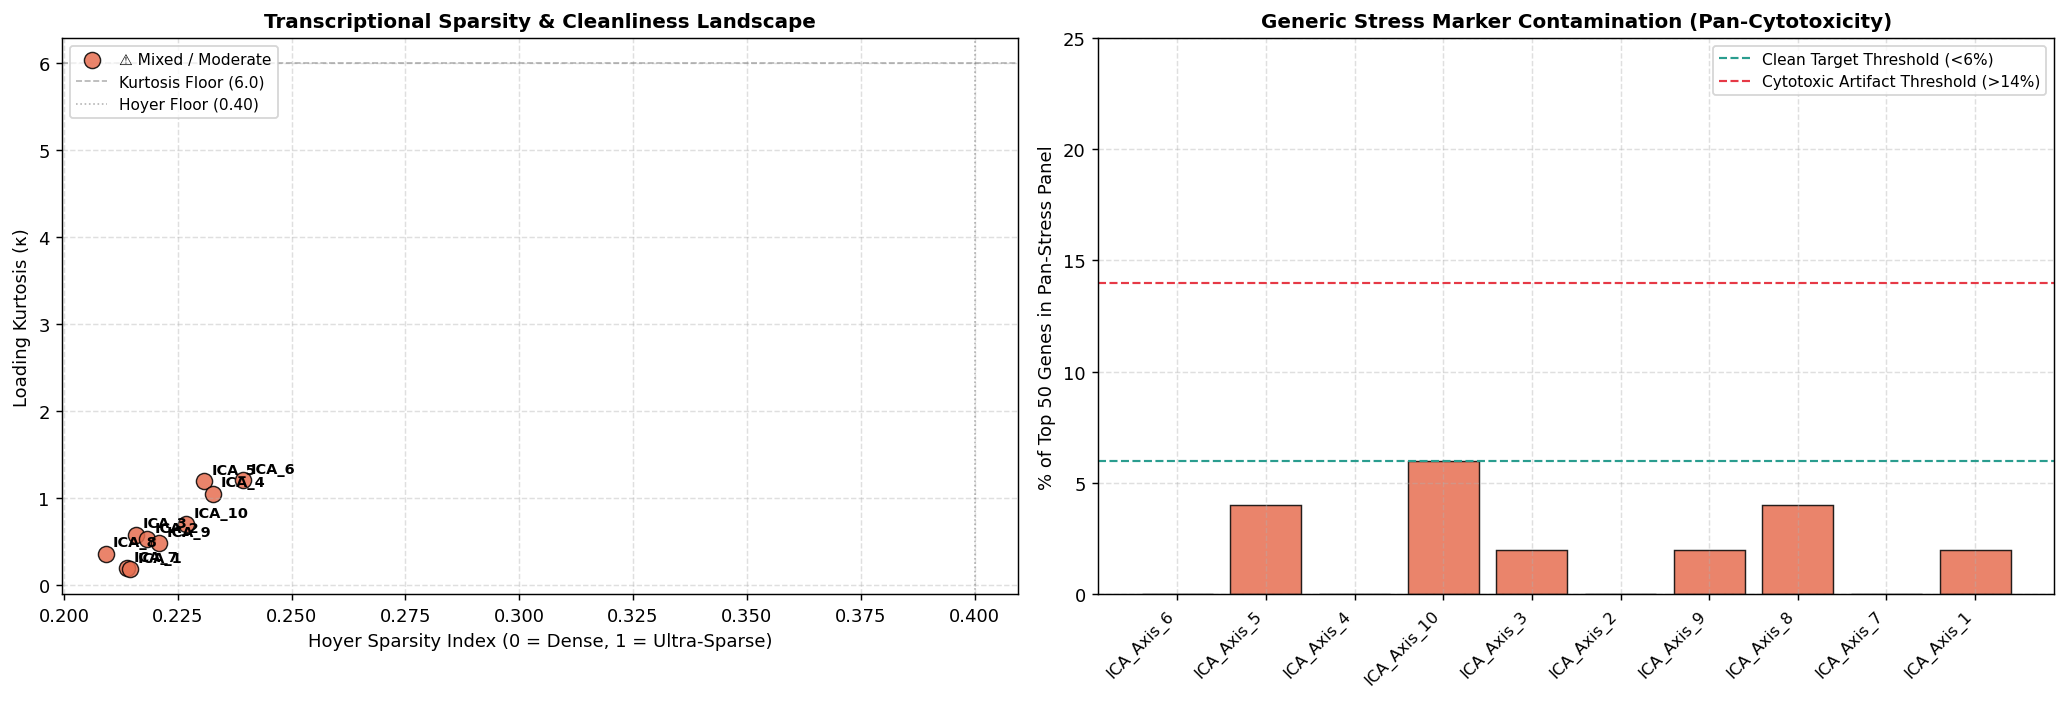

In [16]:
axis_names = [c for c in merged_all.columns if c.startswith(f"{axis_prefix}_")]
axis_names = sorted(axis_names, key=lambda x: int(x.split("_")[-1]))
symbols = [ensembl_to_symbol.get(g.split(".")[0], g) for g in active_ensembl_genes]

print("=" * 115)
print(f"🧼 RUNNING FULL TRANSCRIPTIONAL PURITY SWEEP ACROSS ALL {len(axis_names)} AXES")
print(f"   ↳ Detected Subspace Format: {axis_prefix}")
print("=" * 115)

purity_df = axis_purity_table(
    merged_all[axis_names].values, axis_names, merged_all[active_ensembl_genes].values, symbols
)

format_dict = {
    "Kurtosis (κ)": lambda x: f"{x:5.2f}",
    "Hoyer Sparsity": lambda x: f"{x:5.3f}",
    "Pan-Stress %": lambda x: f"{x:4.1f}%",
    "Total-Signal |r|": lambda x: f"{x:4.2f}",
}
print(purity_df.drop(columns="Cell Count |r|").to_string(index=False, formatters=format_dict))
print("=" * 115)

plot_purity_sweep(purity_df)

## Part 4 - Axis explainers: do the axes track microtubule biology?

Axis decoding starts from the data. Here we start from a hypothesis about microtubule-targeting and antimitotic drugs and
look for the axes that track it, in two independent ways.

1. **Gene module.** Every compound gets a *module score*, the mean z-scored expression of 57 spindle-checkpoint,
   mitotic-kinase, kinesin, kinetochore and tubulin genes. Each axis is correlated with that score. Only genes among the
   5,000 most variable ones can be used, so the module is usually incomplete (4 of 57 genes in the saved draft run).
2. **Known drugs.** Compounds that are known tubulin binders or spindle inhibitors (taxanes, vinca alkaloids, colchicine
   site binders, epothilones, benzimidazoles, Eg5 inhibitors) are marked and every axis is tested for a shift of their
   scores (ROC-AUC, effect size, rank tests). Compounds are matched on the full InChIKey and, failing that, on its first
   14 characters (so stereoisomers and salts of a drug are found too).

An axis supported by both would be a convincing readout of mitotic-arrest biology. Axis signs are arbitrary, so the
better direction is reported.

> **Fix applied.** The InChIKeys of the drug list in the draft notebook were wrong for 20 of the 22 drugs (only colchicine
> and albendazole matched PubChem), so the scan could not find those drugs. The keys in
> `model_benchmarking.explainers.TUBULIN_DRUGS` were looked up by drug name in PubChem. The draft also queried
> PubChem/ChEMBL for every compound when fewer than two drugs matched; that fallback (thousands of web requests) was
> dropped.

### 4.1 Gene module score and axis scan

In [17]:
matched_genes = resolve_gene_columns(MICROTUBULE_GENES, active_ensembl_genes, ensembl_to_symbol)
print("📋 Target Gene Module Search:")
print(f"   ↳ Resolved {len(matched_genes)}/{len(MICROTUBULE_GENES)} genes in the active screen:")
print(f"   ↳ Active Genes: {', '.join(list(matched_genes)[:20])} ... (+{max(0, len(matched_genes) - 20)} more)")

if not matched_genes:
    raise ValueError("Zero target genes matched! Inspect the first elements of active_ensembl_genes.")

compound_module_scores = module_scores(merged_all[list(matched_genes.values())].values)
merged_all["Target_Module_Score"] = compound_module_scores
print(f"✅ Module Scores Computed across N = {len(compound_module_scores):,} compounds:")
print(
    f"   ↳ Mean: {np.mean(compound_module_scores):.4f} | Std: {np.std(compound_module_scores):.4f} | "
    f"Range: [{np.min(compound_module_scores):.2f}, {np.max(compound_module_scores):.2f}]"
)

module_scan_df = scan_axes_for_module(merged_all[axis_names], compound_module_scores, canonical_r)

print("\n" + "=" * 95)
print("🏆 AXES RANKED BY MICROTUBULE MODULE COUPLING:")
print("=" * 95)
shown = ["Axis", "Canonical_r", "Module_Corr_Pearson", "Module_Corr_Spearman", "T_Statistic", "P_Value"]
if canonical_r is None:  # canonical correlations are not defined for unmixed axes
    shown.remove("Canonical_r")
print(module_scan_df[shown].head(8).to_string(index=False, float_format="{:.4f}".format))

winning_axis = module_scan_df.iloc[0]["Axis"]
winning_r = module_scan_df.iloc[0]["Module_Corr_Pearson"]
polarity = 1.0 if winning_r > 0 else -1.0
print(f"\n🎯 PRIMARY MICROTUBULE AXIS: [{winning_axis}]")
print(
    f"   ↳ Correlation: r = {winning_r:+.4f} (p = {module_scan_df.iloc[0]['P_Value']:.2e}) | Polarity: {'Positive (+)' if polarity > 0 else 'Negative (-)'}"
)

### 4.2 Compounds that drive the module
The ten compounds with the highest score on the winning axis (in the direction that supports the module), annotated through
PubChem/ChEMBL, with their module score.

In [18]:
print("=" * 95)
print(f"🧪 TOP 10 MOLECULES DRIVING THE MICROTUBULE PHENOTYPE ALONG {winning_axis}:")
print("=" * 95)
print_module_drivers(merged_all, winning_axis, polarity, compound_module_scores, MERGE_KEY)

plot_module_scan(merged_all, compound_module_scores, module_scan_df, title="Microtubule Signature")

### 4.3 Known tubulin and spindle drugs
Marks the known drugs among the scored compounds and tests every axis for a shift of their scores. A scan needs at least
two matched drugs.

In [19]:
is_reference, matched_details = match_reference_compounds(bio_scores_df[MERGE_KEY].values, TUBULIN_DRUGS)
n_gt_hits = int(is_reference.sum())

print("=" * 95)
print("🧪 SCANNING AXES VIA GROUND-TRUTH MICROTUBULE INHIBITOR INCHIKEYS")
print("=" * 95)
print("🎯 Cohort Matching Results:")
print(f"   ↳ Screened Molecules in Subspace : N = {len(bio_scores_df):,}")
print(f"   ↳ Ground Truth Hits Identified   : N = {n_gt_hits} confirmed microtubule/spindle inhibitors")

if n_gt_hits < 2:
    raise RuntimeError(
        "Insufficient ground-truth microtubule inhibitors in this cohort to perform statistical enrichment."
    )

print("\n📋 Confirmed Microtubule Inhibitors Present in Screen:")
for details in [d for d in matched_details if d is not None][:8]:
    print(f"   • {details[0]:<24} | Class: {details[1]:<30} | Matched via: {details[2]}")
if n_gt_hits > 8:
    print(f"   ↳ (+{n_gt_hits - 8} additional inhibitors)")

reference_scan_df = scan_axes_for_reference_set(bio_scores_df[axis_names], is_reference, canonical_r)

print("\n" + "=" * 95)
print("🏆 TOP AXES ENRICHED FOR GROUND-TRUTH MICROTUBULE INHIBITORS:")
print("=" * 95)
shown = ["Axis", "Canonical_r", "Cohen_d", "ROC_AUC", "P_Value", "Polarity", "KS_Stat"]
if canonical_r is None:
    shown.remove("Canonical_r")
print(reference_scan_df[shown].head(8).to_string(index=False, float_format="{:.4f}".format))

top = reference_scan_df.iloc[0]
print(f"\n🎯 WINNING GROUND-TRUTH AXIS: [{top['Axis']}]")
print(
    f"   ↳ ROC-AUC: {top['ROC_AUC']:.3f} | Effect Size (Cohen's d): {top['Cohen_d']:+.3f} | Significance: p = {top['P_Value']:.2e}"
)

### 4.4 Cross-check with the gene module, and figure
Do the known drugs also score high on the gene module? (Only drugs with a DRUG-seq profile count.) Then the ROC-AUC of every
axis and the score distribution of the best axis.

In [20]:
is_reference_merged = merged_all[MERGE_KEY].isin(set(bio_scores_df.loc[is_reference, MERGE_KEY])).values
separation = reference_module_separation(compound_module_scores, is_reference_merged)

print("=" * 95)
print(f"🔗 CROSS-MODAL TRIANGULATION: GROUND TRUTH DRUGS VS. GENE MODULE (N = {len(merged_all)} Shared RNA Cohort)")
print("=" * 95)
print(f"   ↳ Ground Truth Inhibitors with RNA Profiles: N = {int(is_reference_merged.sum())}")
if separation is None:
    print("   ⚠️ Insufficient ground truth inhibitors overlapped into raw RNA space to perform module correlation.")
else:
    ref_mean, bg_mean, p_module = separation
    print(f"   ↳ Module Z-Score in Ground Truth Drugs : {ref_mean:+.2f}σ")
    print(f"   ↳ Module Z-Score in Background Compounds: {bg_mean:+.2f}σ")
    print(f"   ↳ One-sided Mann-Whitney p = {p_module:.2e}")
    if p_module < 0.05:
        print("   ✅ Ground-truth drugs score significantly higher on the target gene module.")

plot_reference_scan(bio_scores_df, is_reference, reference_scan_df)